In [2]:
from cmcrameri import cm as cmc
import re
import sys
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patheffects as pe

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from tools_eg import *

import os
import pandas as pd
%config InlineBackend.figure_format = "retina"


In [3]:
# ===========================================================================
#  CONFIG
# ===========================================================================
target = "2026-07-13"

BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
EDDY_PRODUCT = "TOEDDIES_better_ADT"        # tried first; the other one is the fallback
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_CTD = BASE / "data/CTD"
DIR_MVP = BASE / "data/MVP_Data_processed"
DIR_FLOATS = BASE / "data/FLOATS"
DIR_SG = BASE / "data/SEAGLIDERS"
DIR_WG = BASE / "data/WAVEGLIDERS"
DIR_XSP = BASE / "data/XSPAR"
MD_CTD_NC = DIR_CTD / "ctd_metadata.nc"

DIR_DRIFTERS = BASE / "data/DRIFTERS/drifters"                    # folder of CSV snapshots
OUT_DIR = BASE / "figures"

# SA Agulhas CTDs: give the .xlsx path if you have it. None = look for an
# 'Agu*.xlsx' file anywhere under data/CTD; if none is found they are skipped.
AGU_CTD_XLSX = None
AGU_CTD_SHEET = "Profile"

LON_MIN, LON_MAX = 6.0, 22.0
LAT_MIN, LAT_MAX = -42.0, -30.0
ZOOM_EXTENT = (8.0, 16.0, -40.0, -34.0)

type_SADCP = "OS150"

# CTD bullet styling: MD orange / Agulhas violet, thin dark edge.
MD_CTD_COLOR = "#FF8C00"
AGU_CTD_COLOR = "#9400D3"
CTD_MS = 3.5
CTD_MEW = 0.3
CTD_MEC = "k"
CTD_ZORDER = 8

BATHY_LEVELS = [100, 200, 500, 1000, 2000, 3000, 4000, 5000]
BATHY_COLOR = "0.45"
BATHY_LW = 0.35
BATHY_LW_DEEP_FACTOR = 1.25
BATHY_LS = "solid"
BATHY_ALPHA = 0.7
BATHY_ZORDER = 2.5
BATHY_LABELS = False

# Eddy contours: bold black, white halo; cyclones solid, anticyclones dashed
EDDY_COLOR = "k"
EDDY_LW = 1.3
EDDY_ZORDER = 5
EDDY_HALO = True
EDDY_HALO_COLOR = "white"
EDDY_HALO_LW = 2.4
EDDY_HALO_ALPHA = 0.85
EDDY_CENTER_MS = 6

ADT_VMIN, ADT_VMAX = -0.7, 1.7
ADT_CMAP_NAME = "vik"       # Crameri 'vik' if cmcrameri is installed, else cmocean balance

# ADT isolines every 0.1 m
ADT_ISO_STEP = 0.1
ADT_ISO_COLOR = "0.15"
ADT_ISO_LW = 0.5
ADT_ISO_ALPHA = 0.85
ADT_ISO_ZORDER = 3.0
ADT_ISO_LABELS = True
ADT_ISO_LABEL_FS = 5

QUIVER_STEP = 2
QUIVER_STEP_ZOOM = 1
QUIVER_SCALE = 110
QUIVER_SCALE_ZOOM = 45
QUIVER_WIDTH = 0.0007
QUIVER_WIDTH_ZOOM = 0.0012
QUIVER_HEADW = 3.0
QUIVER_HEADL = 3.5
QUIVER_ALPHA = 0.9
QUIVER_COLOR = "k"
QUIVER_KEY_SPEED = 1.0

TICK_MAJOR_FULL = 2.0
TICK_MAJOR_ZOOM = 1.0
N_MINOR = 4
GRID_COLOR = "white"
GRID_ALPHA = 0.45
GRID_LW = 0.4
FIG_DPI = 300
FIG_SIZE_FULL = (13, 9)
FIG_SIZE_ZOOM = (12, 9)
# ===========================================================================


In [4]:


def adt_colormap():
    try:
        from cmcrameri import cm as cmc
        print(f"[info] ADT colormap: Crameri '{ADT_CMAP_NAME}'")
        return getattr(cmc, ADT_CMAP_NAME)
    except Exception:
        pass
    try:
        import cmocean
        print("[info] cmcrameri not installed; ADT colormap: cmocean 'balance'")
        return cmocean.cm.balance
    except Exception:
        print("[info] ADT colormap: RdBu_r")
        return plt.get_cmap("RdBu_r")


# ---------------------------------------------------------------------------
#  Dates in file names
# ---------------------------------------------------------------------------
_DATE_RE = re.compile(r"(20\d{2})-?(\d{2})-?(\d{2})")


def file_date(path):
    """First YYYY-MM-DD or YYYYMMDD in the file name -> datetime (None if none)."""
    m = _DATE_RE.search(Path(path).name)
    if not m:
        return None
    try:
        return datetime(int(m.group(1)), int(m.group(2)), int(m.group(3)))
    except ValueError:
        return None


def nearest_date(dates, target):
    dates = [d for d in dates if d is not None]
    if not dates:
        return None
    return min(dates, key=lambda d: abs((d - target).days))


# ---------------------------------------------------------------------------
#  SSH
# ---------------------------------------------------------------------------
def _subset_bounds(ds, name, lo, hi):
    """Slice a coordinate to [lo, hi] whatever its storage order."""
    vals = ds[name].values
    if vals.size > 1 and vals[0] > vals[-1]:
        return {name: slice(hi, lo)}
    return {name: slice(lo, hi)}


def ssh_for_date(target):
    """SSH file in DIR_SSH NEAREST `target` -> (LON, LAT, adt, ugos, vgos, 'YYYY-MM-DD')."""
    try:
        tgt = datetime.strptime(target, "%Y-%m-%d")
    except ValueError:
        raise SystemExit(f"TARGET_DATE '{target}' is not YYYY-MM-DD.")

    files = [f for f in sorted(DIR_SSH.glob("*.nc")) if file_date(f) is not None]
    if not files:
        raise SystemExit(f"No dated .nc files in {DIR_SSH}")
    path = min(files, key=lambda f: abs((file_date(f) - tgt).days))
    d = file_date(path)
    stem = d.strftime("%Y-%m-%d")
    gap = abs((d - tgt).days)
    if gap == 0:
        print(f"SSH file for {target}: {path}")
    else:
        print(f"[warn] no SSH file for {target}; using the nearest, {stem} "
              f"({gap} day{'s' if gap != 1 else ''} away): {path}")

    ds = xr.open_dataset(path)
    sel = {}
    sel.update(_subset_bounds(ds, "longitude", LON_MIN, LON_MAX))
    sel.update(_subset_bounds(ds, "latitude", LAT_MIN, LAT_MAX))
    sub = ds.sel(**sel)

    nlat, nlon = sub.sizes.get("latitude", 0), sub.sizes.get("longitude", 0)
    if nlat < 2 or nlon < 2:
        full_lat, full_lon = ds["latitude"].values, ds["longitude"].values
        ds.close()
        raise SystemExit(
            f"\nSSH subset is empty or degenerate: {nlat} lat x {nlon} lon.\n"
            f"  requested window : lon {LON_MIN}..{LON_MAX}, lat {LAT_MIN}..{LAT_MAX}\n"
            f"  file covers      : lon {full_lon.min():.3f}..{full_lon.max():.3f}, "
            f"lat {full_lat.min():.3f}..{full_lat.max():.3f}\n"
            f"Adjust LON_MIN/LON_MAX/LAT_MIN/LAT_MAX to overlap the file.")

    LON, LAT = sub["longitude"].values, sub["latitude"].values
    adt = np.atleast_2d(np.squeeze(sub["adt"].values))
    u = np.atleast_2d(np.squeeze(sub["ugos"].values))
    v = np.atleast_2d(np.squeeze(sub["vgos"].values))
    ds.close()

    if LAT.size > 1 and LAT[0] > LAT[-1]:
        LAT = LAT[::-1]
        adt, u, v = adt[::-1, :], u[::-1, :], v[::-1, :]
    if LON.size > 1 and LON[0] > LON[-1]:
        LON = LON[::-1]
        adt, u, v = adt[:, ::-1], u[:, ::-1], v[:, ::-1]

    print(f"  grid {LAT.size} lat x {LON.size} lon; lon {LON.min():.3f}..{LON.max():.3f}, "
          f"lat {LAT.min():.3f}..{LAT.max():.3f}")
    return LON, LAT, adt, u, v, stem


# ---------------------------------------------------------------------------
#  TOEddies (shapefiles or geojson, read with geopandas)
# ---------------------------------------------------------------------------
def _geom_coords(geom):
    """Polygon -> exterior ring; MultiPolygon -> first polygon (as the original);
    Point -> (x, y)."""
    if geom is None or geom.is_empty:
        return None
    if geom.geom_type == "Polygon":
        return list(geom.exterior.coords)
    if geom.geom_type == "MultiPolygon":
        return list(geom.geoms[0].exterior.coords)
    if geom.geom_type == "Point":
        return (geom.x, geom.y)
    if geom.geom_type in ("LineString", "LinearRing"):
        return list(geom.coords)
    return None


def eddies_for_date(ssh_date):
    """Eddy geometry for the plotted SSH date (nearest available date, with warning)."""
    import geopandas as gpd

    tgt = datetime.strptime(ssh_date, "%Y-%m-%d")
    order = [EDDY_PRODUCT] + [k for k in DIR_EDDIES if k != EDDY_PRODUCT]
    for product in order:
        d = DIR_EDDIES[product]
        if not d.exists():
            continue
        files = [f for f in d.iterdir()
                 if f.suffix.lower() in (".shp", ".geojson", ".json") and file_date(f)]
        best = nearest_date([file_date(f) for f in files], tgt)
        if best is None:
            continue
        gap = abs((best - tgt).days)
        if gap > 0 and product == EDDY_PRODUCT:
            # the exact day may exist in the fallback product
            other = [DIR_EDDIES[k] for k in order[1:] if DIR_EDDIES[k].exists()]
            if any(file_date(f) == tgt for o in other for f in o.iterdir()):
                print(f"[info] no {product} file for {ssh_date}; trying the fallback product")
                continue
        files = [f for f in files if file_date(f) == best]
        if gap:
            print(f"[warn] no eddy file for the SSH date {ssh_date}; using "
                  f"{best:%Y-%m-%d} ({gap} day{'s' if gap != 1 else ''} away)")
        print(f"Eddies: {product}, {best:%Y-%m-%d} ({len(files)} files)")

        out = {k: [] for k in ("ac_out", "cy_out", "ac_ms", "cy_ms", "ac_cen", "cy_cen")}
        for f in files:
            name = f.name.lower()
            kind = "ac" if "anti" in name else "cy"
            part = ("out" if "outcontour" in name else "ms" if "maxspeed" in name
                    else "cen" if "center" in name else None)
            if part is None:
                continue
            for geom in gpd.read_file(f).geometry:
                c = _geom_coords(geom)
                if c is not None:
                    out[f"{kind}_{part}"].append(c)
        return out

    print("[warn] no TOEddies files found; eddies skipped.")
    return {}


# ---------------------------------------------------------------------------
#  CTD positions
# ---------------------------------------------------------------------------
def _find_position_var(ds, short, std_name, units):
    """Name of the lat (or lon) variable of the cast START position.
    Matches the name, the standard_name or the units, and prefers names without
    'end' / 'bottom' (ctd_metadata.nc also stores end and bottom positions)."""
    cands = []
    for n, v in ds.variables.items():
        nl = n.lower()
        sn = str(v.attrs.get("standard_name", "")).lower()
        un = str(v.attrs.get("units", "")).lower()
        if nl in (short, std_name) or nl.startswith(short) or sn == std_name or un == units:
            cands.append(n)
    if not cands:
        return None

    def rank(n):
        nl = n.lower()
        return (("end" in nl) or ("bottom" in nl),       # start position first
                nl not in (short, std_name),             # exact names first
                "start" not in nl)
    return sorted(cands, key=rank)[0]


def load_ctd_positions_nc(path, label="MD CTD"):
    """Cast positions from ctd_metadata.nc (variables latitude / longitude)."""
    if not Path(path).exists():
        print(f"[warn] {label}: file not found: {path}; no positions drawn.")
        return np.array([]), np.array([])
    ds = xr.open_dataset(path)
    lat = _find_position_var(ds, "lat", "latitude", "degrees_north")
    lon = _find_position_var(ds, "lon", "longitude", "degrees_east")
    if lat is None or lon is None:
        ds.close()
        raise SystemExit(f"{label}: no latitude/longitude variable found in {path}.\n"
                         f"Variables: {list(ds.variables)}")
    print(f"{label}: positions from variables '{lat}' / '{lon}'")
    lats = np.asarray(ds[lat].values, float).ravel()
    lons = np.asarray(ds[lon].values, float).ravel()
    span = ""
    if "time_start" in ds.variables:
        t = ds["time_start"].values
        if np.issubdtype(t.dtype, np.datetime64):
            t = t[~np.isnat(t)]
            if t.size:
                span = (f"; dates {np.datetime_as_string(t.min(), 'D')} .. "
                        f"{np.datetime_as_string(t.max(), 'D')}")
    ds.close()
    ok = np.isfinite(lats) & np.isfinite(lons)
    print(f"{label}: {ok.sum()} CTD positions from {path}{span}")
    return lons[ok], lats[ok]


def _excel_serial_to_date(x):
    try:
        return datetime(1899, 12, 30) + timedelta(days=float(x))
    except (TypeError, ValueError):
        return None


def find_agulhas_xlsx():
    if AGU_CTD_XLSX:
        return Path(AGU_CTD_XLSX)
    hits = sorted(p for p in DIR_CTD.rglob("*.xlsx") if "agu" in p.name.lower())
    if hits:
        print(f"[info] SA Agulhas CTD file found: {hits[0]}")
        return hits[0]
    print("[info] no SA Agulhas CTD file (Agu*.xlsx) under data/CTD; "
          "Agulhas CTDs not drawn. Set AGU_CTD_XLSX if you have it elsewhere.")
    return None


def load_ctd_positions_xlsx(path, sheet=None, dedupe_by_station=False, label="CTD"):
    """
    CTD positions from an .xlsx file -> (lons, lats). Header row found
    automatically (first row with a cell starting with 'lat'); columns matched
    case-insensitively. With dedupe_by_station, consecutive rows of the same
    station (one row per depth bin) collapse to one position.
    """
    if path is None:
        return np.array([]), np.array([])
    if not Path(path).exists():
        print(f"[warn] {label}: file not found: {path}; no positions drawn.")
        return np.array([]), np.array([])
    try:
        from openpyxl import load_workbook
    except ImportError:
        print(f"[warn] {label}: reading .xlsx needs openpyxl "
              "(python -m pip install openpyxl); skipped.")
        return np.array([]), np.array([])

    wb = load_workbook(path, read_only=True, data_only=True)
    ws = wb[sheet] if (sheet and sheet in wb.sheetnames) else wb[wb.sheetnames[0]]
    if sheet and sheet not in wb.sheetnames:
        print(f"[warn] {label}: sheet '{sheet}' not in {path}; using '{ws.title}'. "
              f"Sheets: {', '.join(wb.sheetnames)}")
    rows = ws.iter_rows(values_only=True)

    header, i_lat = None, None
    for r in rows:
        cells = ["" if c is None else str(c).strip().lower() for c in r]
        for i, c in enumerate(cells):
            if c.startswith("lat"):
                header, i_lat = cells, i
                break
        if header is not None:
            break
    if header is None:
        wb.close()
        print(f"[warn] {label}: no latitude column found in {path}; skipped.")
        return np.array([]), np.array([])

    def find(*prefixes):
        for i, c in enumerate(header):
            if any(c.startswith(p) for p in prefixes):
                return i
        return None

    i_lon = find("lon", "long")
    i_stn = find("station", "cast", "point")
    i_date = find("date", "mm/dd")
    if i_lon is None:
        wb.close()
        print(f"[warn] {label}: no longitude column found in {path}; skipped.")
        return np.array([]), np.array([])

    lats, lons, dates, last_key = [], [], [], object()
    for r in rows:
        if r is None or max(i_lat, i_lon) >= len(r):
            continue
        try:
            la, lo = float(r[i_lat]), float(r[i_lon])
        except (TypeError, ValueError):
            continue
        key = (r[i_stn] if (i_stn is not None and i_stn < len(r))
               else (round(la, 4), round(lo, 4)))
        if dedupe_by_station and key == last_key:
            continue
        last_key = key
        lats.append(la)
        lons.append(lo)
        if i_date is not None and i_date < len(r):
            d = _excel_serial_to_date(r[i_date])
            if d:
                dates.append(d)
    wb.close()

    lats, lons = np.array(lats, float), np.array(lons, float)
    if lats.size and "[s]" in header[i_lat] and (lats > 0).all():
        print(f"[warn] {label}: latitude header says [S] but values are positive; flipping sign.")
        lats = -lats
    if lons.size and "[w]" in header[i_lon] and (lons > 0).all():
        print(f"[warn] {label}: longitude header says [W] but values are positive; flipping sign.")
        lons = -lons
    span = f"; dates {min(dates):%Y-%m-%d} .. {max(dates):%Y-%m-%d}" if dates else ""
    print(f"{label}: {lats.size} CTD positions from {path} (sheet '{ws.title}'){span}")
    return lons, lats


# ---------------------------------------------------------------------------
#  Drawing
# ---------------------------------------------------------------------------
def draw_adt_isolines(ax, LON, LAT, adt):
    if not np.isfinite(adt).any():
        print("[warn] ADT field is all-NaN; isolines skipped.")
        return None
    lo = np.floor(np.nanmin(adt) / ADT_ISO_STEP) * ADT_ISO_STEP
    hi = np.ceil(np.nanmax(adt) / ADT_ISO_STEP) * ADT_ISO_STEP
    levels = np.arange(lo, hi + ADT_ISO_STEP / 2.0, ADT_ISO_STEP)
    cs = ax.contour(LON, LAT, adt, levels=levels, colors=ADT_ISO_COLOR,
                    linewidths=ADT_ISO_LW, linestyles="solid",
                    transform=ccrs.PlateCarree(), zorder=ADT_ISO_ZORDER, alpha=ADT_ISO_ALPHA)
    if ADT_ISO_LABELS:
        ax.clabel(cs, fmt="%.1f", fontsize=ADT_ISO_LABEL_FS, inline=True, inline_spacing=2)
    print(f"ADT isolines: {levels.size} levels, {levels[0]:.1f} .. {levels[-1]:.1f} m, "
          f"step {ADT_ISO_STEP:g} m")
    return cs


def draw_bathymetry(ax, extent):
    if not FNAME_BATHY.exists():
        print(f"[warn] bathymetry not found: {FNAME_BATHY}")
        return
    lo0, lo1, la0, la1 = extent
    ds = xr.open_dataset(FNAME_BATHY)
    dv = next((v for v in ("topo", "elevation", "z", "Band1", "depth") if v in ds.variables), None)
    if dv is None:
        ds.close()
        print(f"[warn] no elevation variable in {FNAME_BATHY}; bathymetry skipped.")
        return
    latn = "lat" if "lat" in ds.coords else "latitude"
    lonn = "lon" if "lon" in ds.coords else "longitude"
    lat, lon = ds[latn].values, ds[lonn].values
    la_ok = (lat >= la0 - 1) & (lat <= la1 + 1)
    lo_ok = (lon >= lo0 - 1) & (lon <= lo1 + 1)
    elev = ds[dv].isel({latn: np.flatnonzero(la_ok), lonn: np.flatnonzero(lo_ok)})
    elev = np.squeeze(elev.transpose(latn, lonn).values).astype(float)
    ds.close()
    lat, lon = lat[la_ok], lon[lo_ok]

    n = len(BATHY_LEVELS)
    lws = ([BATHY_LW * (1.0 + (BATHY_LW_DEEP_FACTOR - 1.0) * i / (n - 1)) for i in range(n)]
           if n > 1 else [BATHY_LW])
    cs = ax.contour(lon, lat, -elev, levels=BATHY_LEVELS, colors=BATHY_COLOR,
                    linewidths=lws, linestyles=BATHY_LS, transform=ccrs.PlateCarree(),
                    zorder=BATHY_ZORDER, alpha=BATHY_ALPHA)
    if BATHY_LABELS:
        ax.clabel(cs, levels=BATHY_LEVELS, fmt="%d m", fontsize=5, inline=True, inline_spacing=2)


def draw_eddies(ax, eddies):
    eddy_pe = ([pe.withStroke(linewidth=EDDY_HALO_LW, foreground=EDDY_HALO_COLOR,
                              alpha=EDDY_HALO_ALPHA)] if EDDY_HALO else None)
    for pts in eddies.get("ac_out", []) + eddies.get("ac_ms", []):
        ax.plot(*zip(*pts), "--", color=EDDY_COLOR, lw=EDDY_LW, zorder=EDDY_ZORDER,
                path_effects=eddy_pe, transform=ccrs.PlateCarree())
    for pts in eddies.get("cy_out", []) + eddies.get("cy_ms", []):
        ax.plot(*zip(*pts), "-", color=EDDY_COLOR, lw=EDDY_LW, zorder=EDDY_ZORDER,
                path_effects=eddy_pe, transform=ccrs.PlateCarree())
    for lo, la in eddies.get("ac_cen", []) + eddies.get("cy_cen", []):
        ax.plot(lo, la, "+", color=EDDY_COLOR, ms=EDDY_CENTER_MS, mew=1.4,
                zorder=EDDY_ZORDER + 1, path_effects=eddy_pe, transform=ccrs.PlateCarree())


def draw_currents(fig, ax, LON, LAT, u, v, is_zoom):
    """Geostrophic current vectors: uniform thin arrows, length = speed."""
    for nm, arr in (("ugos", u), ("vgos", v)):
        if np.ndim(arr) != 2:
            raise SystemExit(f"{nm} is {np.ndim(arr)}-D, expected 2-D.")
    s = QUIVER_STEP_ZOOM if is_zoom else QUIVER_STEP
    q_scale = QUIVER_SCALE_ZOOM if is_zoom else QUIVER_SCALE
    q_width = QUIVER_WIDTH_ZOOM if is_zoom else QUIVER_WIDTH
    MLON, MLAT = np.meshgrid(LON, LAT)
    q = ax.quiver(MLON[::s, ::s], MLAT[::s, ::s], u[::s, ::s], v[::s, ::s],
                  color=QUIVER_COLOR, alpha=QUIVER_ALPHA, transform=ccrs.PlateCarree(),
                  scale=q_scale, scale_units="width", width=q_width,
                  headwidth=QUIVER_HEADW, headlength=QUIVER_HEADL,
                  headaxislength=QUIVER_HEADL * 0.9, zorder=4)
    ax.quiverkey(q, 0.86, 1.02, QUIVER_KEY_SPEED, f"{QUIVER_KEY_SPEED:g} m s$^{{-1}}$",
                 labelpos="E", coordinates="axes", fontproperties={"size": 8})


def draw_ctds(ax, md_ctd, ag_ctd):
    for (lons, lats), col in ((md_ctd, MD_CTD_COLOR), (ag_ctd, AGU_CTD_COLOR)):
        if lons.size:
            ax.plot(lons, lats, "o", ls="None", color=col, ms=CTD_MS, mec=CTD_MEC,
                    mew=CTD_MEW, zorder=CTD_ZORDER, transform=ccrs.PlateCarree())


def setup_ticks(ax, extent, major=None):
    import matplotlib.ticker as mticker
    from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

    lo0, lo1, la0, la1 = extent
    if major is None:
        major = TICK_MAJOR_ZOOM if (lo1 - lo0) <= 10 else TICK_MAJOR_FULL
    xt = np.arange(np.floor(lo0 / major) * major, np.ceil(lo1 / major) * major + 1e-6, major)
    yt = np.arange(np.floor(la0 / major) * major, np.ceil(la1 / major) * major + 1e-6, major)
    ax.set_xticks(xt, crs=ccrs.PlateCarree())
    ax.set_yticks(yt, crs=ccrs.PlateCarree())
    ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax.yaxis.set_major_formatter(LatitudeFormatter())
    ax.xaxis.set_minor_locator(mticker.AutoMinorLocator(N_MINOR))
    ax.yaxis.set_minor_locator(mticker.AutoMinorLocator(N_MINOR))
    ax.tick_params(which="major", length=6, width=0.8, direction="out",
                   top=True, right=True, labelsize=9)
    ax.tick_params(which="minor", length=3, width=0.5, direction="out", top=True, right=True)
    ax.tick_params(labeltop=False, labelright=False)
    ax.grid(which="major", color=GRID_COLOR, alpha=GRID_ALPHA, linewidth=GRID_LW,
            linestyle=":", zorder=6)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")



In [5]:

mvp_files = sorted(os.listdir(DIR_MVP))

transect 1: 66 files, 65 casts with a position
transect 2: 90 files, 90 casts with a position
transect 3: 26 files, 26 casts with a position
transect 4: 42 files, 42 casts with a position
transect 5: 56 files, 56 casts with a position
transect 6: 24 files, 24 casts with a position
transect 7: 52 files, 52 casts with a position
transect 8: 20 files, 20 casts with a position
transect 9: 52 files, 52 casts with a position
transect 10: 104 files, 104 casts with a position
transect 11: 16 files, 16 casts with a position
transect 12: 118 files, 118 casts with a position
transect 13: 60 files, 60 casts with a position
transect 14: 100 files, 100 casts with a position
transect 15: 118 files, 118 casts with a position
transect 16: 68 files, 68 casts with a position
'mr_float_soton_positions.csv' -> 'Float MR SOTON': 326 positions
'mr_float_ugot_positions.csv' -> 'Float MR UGOT': 322 positions
'uvp_float_6596_locations.csv' -> 'Float UVP 6596': 25 positions
'uvp_float_6597_locations.csv' -> 'Flo

/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_33716/3480194806.py:99: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dff[tcol] = pd.to_datetime(dff[tcol], dayfirst=True, errors="coerce")


Saved /Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/2026-07-13_WHIRLS_adt_isolines_ctd_mvp_floats_gliders.png


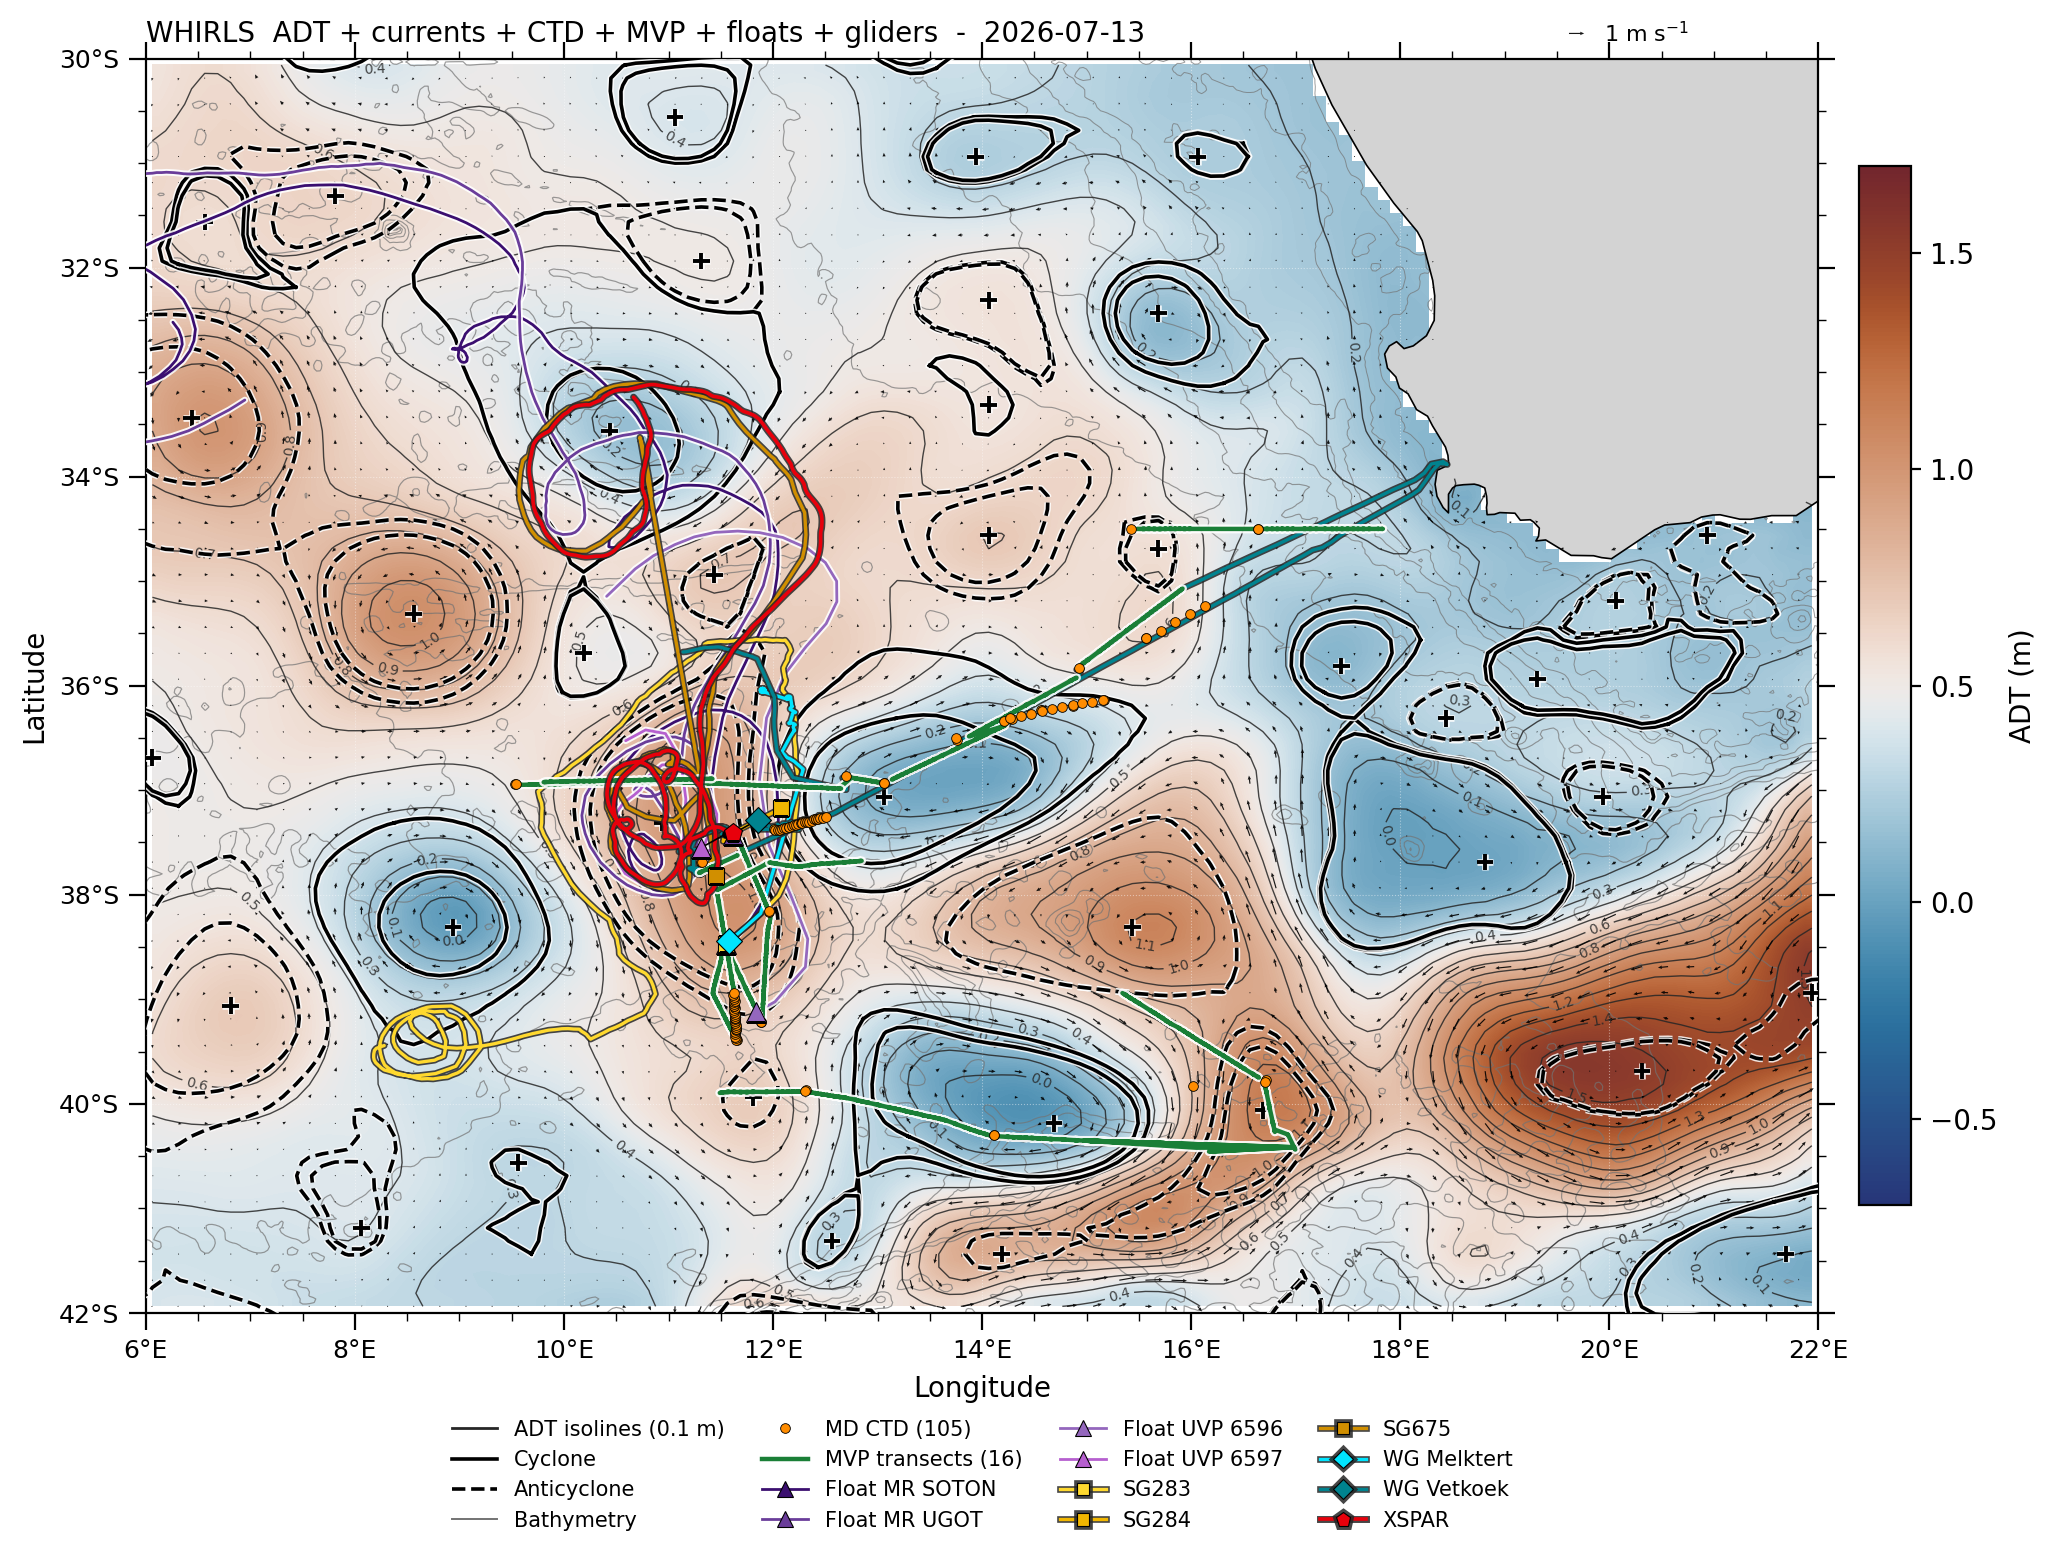

In [92]:
import re
import matplotlib.patheffects as pe

# ---------------------------------------------------------------------------
# MVP transects -> one position per cast
# ---------------------------------------------------------------------------
sadcp = cascade_add_time(xr.open_dataset(SADCP_FILES[type_SADCP]))
sadcp = sadcp.sortby("time")
sadcp = sadcp.isel(time=~sadcp.indexes["time"].duplicated())

transect_names = sorted((f for f in mvp_files if f.startswith('transect ')),
                        key=lambda f: int(f.split()[-1]))
mvp_tracks = {}                # {transect_num: (lon_per_cast, lat_per_cast)}

for name in transect_names:
    transect_num = int(name.split()[-1])
    transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{name}/'
    files = sorted(Path(transect_path).glob("*.csv"))
    dfs = []
    for k, fcsv in enumerate(files):
        df = pd.read_csv(fcsv)
        df["CAST"] = k          # one processed CSV file = one MVP cast
        dfs.append(df)
    mvp_trans = pd.concat(dfs, ignore_index=True)

    if mvp_trans[["LON (°E)", "LAT (°N)"]].isna().any().any():
        sadcp_tr = sadcp_for_transect(mvp_trans, sadcp)
        sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min",
                                       keep=("LATITUDE", "LONGITUDE"))
        mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
        mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

    casts = (mvp_trans.assign(_t=pd.to_datetime(mvp_trans["TIME"]))
                      .groupby("CAST")
                      .agg(lon=("LON (°E)", "mean"), lat=("LAT (°N)", "mean"), t=("_t", "min"))
                      .dropna(subset=["lon", "lat"])
                      .sort_values("t"))
    mvp_tracks[transect_num] = (casts["lon"].values, casts["lat"].values)
    print(f"transect {transect_num}: {len(files)} files, {len(casts)} casts with a position")

# ---------------------------------------------------------------------------
# Floats -> one named track per file
# ---------------------------------------------------------------------------
FLOAT_NAMES = {}               # optional overrides, e.g. {"mr_2.csv": "MR SOTON"}
FLOAT_COLORS = ["#3b0f70", "#6a3d9a", "#9467bd", "#b65fcf"]   # four shades of purple
DROP_WORDS = {"track", "tracks", "traj", "locations", "trajectory", "positions", "position", "data", "float"}

def float_label(fname):
    """'uvp_6596.csv' -> 'UVP 6596', 'mr_ugot_track.csv' -> 'MR UGOT'."""
    if fname in FLOAT_NAMES:
        return FLOAT_NAMES[fname]
    stem = Path(fname).stem
    prefix = "uvp" if stem.lower().startswith("uvp") else "mr"
    rest = re.split(r"[_\-\s.]+", stem[len(prefix):])
    rest = [w for w in rest if w and w.lower() not in DROP_WORDS]
    return " ".join([prefix.upper()] + [w.upper() for w in rest])

float_tracks = []              # [(label, lon, lat), ...]
for ff in sorted(os.listdir(DIR_FLOATS)):
    if not (ff.startswith('uvp') or ff.startswith('mr')) or not ff.endswith(".csv"):
        continue
    dff = pd.read_csv(DIR_FLOATS / ff)
    tcol = next((c for c in dff.columns if c.lower() in ("time", "date", "datetime", "juld")), None)
    if tcol is not None:
        dff = dff.assign(_t=pd.to_datetime(dff[tcol], errors="coerce")).sort_values("_t")
    lon_float = pd.to_numeric(dff['longitude'], errors="coerce").values
    lat_float = pd.to_numeric(dff['latitude'], errors="coerce").values
    ok = np.isfinite(lon_float) & np.isfinite(lat_float)
    if ok.any():
        float_tracks.append((float_label(ff), lon_float[ok], lat_float[ok]))
        print(f"'{ff}' -> 'Float {float_label(ff)}': {ok.sum()} positions")

# ---------------------------------------------------------------------------
# Gliders -> one named track per file (SGxxx, SeaExplorer = SGSE)
# ---------------------------------------------------------------------------
def glider_label(fname):
    """'sg283_track.csv' -> 'SG283', 'seaexplorer.csv' -> 'SGSE'."""
    stem = Path(fname).stem.lower()
    if "seaexplorer" in stem:
        return "SGSE"
    m = re.search(r"sg\s*_?(\d+)", stem)
    return f"SG{m.group(1)}" if m else Path(fname).stem.upper()

glider_files = sorted(f for f in os.listdir(DIR_SG) if f.endswith(".csv"))
glider_tracks = []             # [(label, lon, lat), ...]
for ff in glider_files:
    # sep=None: detects ; , or tab per file; utf-8-sig: removes a hidden BOM
    dff = pd.read_csv(DIR_SG / ff, sep=None, engine="python", encoding="utf-8-sig")
    dff.columns = dff.columns.str.strip().str.lower()

    tcol = next((c for c in dff.columns if c in ("time", "date", "datetime", "timestamp")), None)
    lon_c = next((c for c in dff.columns if c.startswith("lon")), None)
    lat_c = next((c for c in dff.columns if c.startswith("lat")), None)
    if lon_c is None or lat_c is None:
        print(f"!! {ff}: columns are {list(dff.columns)}")
        continue

    if tcol is not None:
        dff[tcol] = pd.to_datetime(dff[tcol], dayfirst=True, errors="coerce")
        dff = dff.sort_values(tcol)
    lon_glider = pd.to_numeric(dff[lon_c], errors="coerce").values
    lat_glider = pd.to_numeric(dff[lat_c], errors="coerce").values
    ok = np.isfinite(lon_glider) & np.isfinite(lat_glider)
    if ok.any():
        glider_tracks.append((glider_label(ff), lon_glider[ok], lat_glider[ok]))
        print(f"'{ff}' -> '{glider_label(ff)}': {ok.sum()} positions")

# SG numbers first in order, SGSE last
glider_tracks.sort(key=lambda g: (g[0] == "SGSE", g[0]))

# ---------------------------------------------------------------------------
# Wave gliders -> one named track per file
# ---------------------------------------------------------------------------
WAVEGLIDER_FILES = [(DIR_WG / "melktert_track.csv", "WG Melktert"),
                    (DIR_WG / "vetkoek_track.csv",  "WG Vetkoek")]

wg_tracks = []                 # [(label, lon, lat), ...]
for path, label in WAVEGLIDER_FILES:
    if not path.exists():
        print(f"!! missing {path}")
        continue
    dfw = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig")
    dfw.columns = dfw.columns.str.strip().str.lower()
    tcol = next((c for c in dfw.columns if c in ("time", "date", "datetime", "timestamp")), None)
    lon_c = next((c for c in dfw.columns if c.startswith("lon")), None)
    lat_c = next((c for c in dfw.columns if c.startswith("lat")), None)
    if lon_c is None or lat_c is None:
        print(f"!! {path.name}: columns are {list(dfw.columns)}")
        continue
    if tcol is not None:
        dfw[tcol] = pd.to_datetime(dfw[tcol], dayfirst=True, errors="coerce")
        dfw = dfw.sort_values(tcol)
    lo = pd.to_numeric(dfw[lon_c], errors="coerce").values
    la = pd.to_numeric(dfw[lat_c], errors="coerce").values
    ok = np.isfinite(lo) & np.isfinite(la)
    if ok.any():
        wg_tracks.append((label, lo[ok], la[ok]))
        print(f"'{path.name}' -> '{label}': {ok.sum()} positions")
# ---------------------------------------------------------------------------
# XSPAR -> one named track per file
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# XSPAR -> one track, sorted in time, no straight jumps
# ---------------------------------------------------------------------------
XSPAR_MAX_GAP_KM = 30          # break the line where two fixes are further apart

def break_long_jumps(lo, la, max_km):
    """Insert NaN between consecutive fixes more than max_km apart."""
    dx = np.deg2rad(np.diff(lo)) * np.cos(np.deg2rad(0.5 * (la[1:] + la[:-1])))
    d = 6371.0 * np.hypot(dx, np.deg2rad(np.diff(la)))
    cut = np.flatnonzero(d > max_km) + 1
    return np.insert(lo, cut, np.nan), np.insert(la, cut, np.nan), len(cut)

xspar_tracks = []              # [(label, lon, lat), ...]
for ff in sorted(f for f in os.listdir(DIR_XSP) if f.lower().endswith(".csv")):
    dfx = pd.read_csv(DIR_XSP / ff, sep=None, engine="python", encoding="utf-8-sig")
    dfx.columns = dfx.columns.str.strip().str.lower()
    print(f"{ff}: columns {list(dfx.columns)}")
    print(dfx.head(3).to_string())

    tcol = next((c for c in dfx.columns if "time" in c or "date" in c), None)
    lon_c = next((c for c in dfx.columns if c.startswith("lon")), None)
    lat_c = next((c for c in dfx.columns if c.startswith("lat")), None)
    if lon_c is None or lat_c is None:
        print(f"!! {ff}: no lon/lat column")
        continue

    if tcol is None:
        print(f"!! {ff}: no time column -> rows plotted in file order")
    else:
        t1 = pd.to_datetime(dfx[tcol], dayfirst=True, errors="coerce")
        t2 = pd.to_datetime(dfx[tcol], dayfirst=False, errors="coerce")
        dfx["_t"] = t1 if t1.notna().sum() >= t2.notna().sum() else t2
        print(f"   time column '{tcol}': {dfx['_t'].notna().sum()}/{len(dfx)} parsed, "
              f"{dfx['_t'].min()} -> {dfx['_t'].max()}")
        dfx = dfx.dropna(subset=["_t"]).sort_values("_t").drop_duplicates("_t")

    lo = pd.to_numeric(dfx[lon_c], errors="coerce").values
    la = pd.to_numeric(dfx[lat_c], errors="coerce").values
    ok = np.isfinite(lo) & np.isfinite(la)
    lo, la = lo[ok], la[ok]
    if lo.size:
        lo_b, la_b, n_cut = break_long_jumps(lo, la, XSPAR_MAX_GAP_KM)
        xspar_tracks.append(("XSPAR", lo_b, la_b))
        print(f"'{ff}' -> 'XSPAR': {lo.size} positions, line broken at {n_cut} jumps > {XSPAR_MAX_GAP_KM} km")
# ---------------------------------------------------------------------------
# Map
# ---------------------------------------------------------------------------
MVP_COLOR = "#1a7f37"
MVP_LW = 1.6
MVP_ZORDER = 7
MVP_LABELS = False
line_halo = [pe.Stroke(linewidth=MVP_LW + 1.6, foreground="white", alpha=0.9), pe.Normal()]

FLOAT_LW = 1.0
FLOAT_MS = 7.5                 # deployment triangle
FLOAT_ZORDER = 6.5
float_halo = [pe.Stroke(linewidth=FLOAT_LW + 1.4, foreground="white", alpha=0.9), pe.Normal()]

# Gliders: gold -> amber shades with a thin DARK outline (reads on blue, brown and white)
GLIDER_COLORS = ["#ffd92f", "#f2b701", "#d18f00", "#a86b00"]
GLIDER_LW = 1.2
GLIDER_MS = 6                  # deployment square
GLIDER_ZORDER = 6.8
glider_halo = [pe.Stroke(linewidth=GLIDER_LW + 1.2, foreground="0.15", alpha=0.85), pe.Normal()]

# Wave gliders: cyan / dark turquoise with a thin dark outline
WG_COLORS = ["#00e5ff", "#00838f"]
WG_LW = 1.2
WG_MS = 6.5                    # deployment diamond
WG_ZORDER = 6.9
wg_halo = [pe.Stroke(linewidth=WG_LW + 1.2, foreground="0.15", alpha=0.85), pe.Normal()]

XSPAR_COLOR = "#e8000b"        # bright red, dark outline so it doesn't blend into brown ADT
XSPAR_LW = 1.3
XSPAR_MS = 7                   # deployment pentagon
XSPAR_ZORDER = 7.1
xspar_halo = [pe.Stroke(linewidth=XSPAR_LW + 1.2, foreground="0.15", alpha=0.85), pe.Normal()]

DEPLOY_ZORDER = 1000           # deployment markers on top of everything
import matplotlib.transforms as mtransforms

# Deployment markers that overlap: shift them apart (in points) with a leader line
# to the true position. Keys are the legend names.
DEPLOY_NUDGE = {"WG Vetkoek":     ( 9,  5),
                "Float UVP 6597": (-9, -5)}

def draw_deploy(ax, lon, lat, marker, ms, col, name):
    """Deployment marker; if `name` is in DEPLOY_NUDGE, draw it offset with a thin
    leader line and a small black dot at the real deployment position."""
    base = ccrs.PlateCarree()._as_mpl_transform(ax)
    dx, dy = DEPLOY_NUDGE.get(name, (0, 0))
    tr = base
    if dx or dy:
        tr = mtransforms.offset_copy(base, fig=ax.figure, x=dx, y=dy, units="points")
        ax.annotate("", xy=(lon, lat), xycoords=base, xytext=(dx, dy),
                    textcoords="offset points", zorder=DEPLOY_ZORDER - 1,
                    arrowprops=dict(arrowstyle="-", color="k", lw=0.6,
                                    shrinkA=0, shrinkB=0))
        ax.plot(lon, lat, "o", ms=2, color="k", transform=base, zorder=DEPLOY_ZORDER)
    ax.plot(lon, lat, marker, ms=ms, mfc=col, mec="k", mew=0.4, alpha=1,
            transform=tr, zorder=DEPLOY_ZORDER + 1)
extent = (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX)

LON, LAT, adt, ugos, vgos, date_stem = ssh_for_date(target)
eddies = eddies_for_date(date_stem)
md_ctd = load_ctd_positions_nc(MD_CTD_NC, label="MD CTD")
ag_ctd = load_ctd_positions_xlsx(find_agulhas_xlsx(), sheet=AGU_CTD_SHEET,
                                 dedupe_by_station=True, label="SA Agulhas CTD")
cmap = adt_colormap()

fig, ax = plt.subplots(figsize=FIG_SIZE_FULL, subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent(list(extent), crs=ccrs.PlateCarree())

img = ax.imshow(adt, extent=[LON.min(), LON.max(), LAT.min(), LAT.max()],
                cmap=cmap, origin="lower", vmin=ADT_VMIN, vmax=ADT_VMAX,
                alpha=0.85, transform=ccrs.PlateCarree(), zorder=1,
                interpolation="bilinear")
cb = fig.colorbar(img, ax=ax, shrink=0.75, pad=0.02)
cb.set_label("ADT (m)")

draw_currents(fig, ax, LON, LAT, ugos, vgos, is_zoom=False)
draw_adt_isolines(ax, LON, LAT, adt)
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray", zorder=2)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.6, zorder=3)
draw_bathymetry(ax, extent)
draw_eddies(ax, eddies)
draw_ctds(ax, md_ctd, ag_ctd)

# --- Floats ---
for (flabel, lo, la), col in zip(float_tracks, FLOAT_COLORS):
    ax.plot(lo, la, "-", color=col, lw=FLOAT_LW, solid_capstyle="round",
            zorder=FLOAT_ZORDER, path_effects=float_halo, transform=ccrs.PlateCarree())
    draw_deploy(ax, lo[0], la[0], "^", FLOAT_MS, col, f"Float {flabel}")

# --- Gliders ---
for (glabel, lo, la), col in zip(glider_tracks, GLIDER_COLORS):
    ax.plot(lo, la, "-", color=col, lw=GLIDER_LW, solid_capstyle="round",
            zorder=GLIDER_ZORDER, path_effects=glider_halo, transform=ccrs.PlateCarree())
    draw_deploy(ax, lo[0], la[0], "s", GLIDER_MS, col, glabel)

# --- Wave gliders ---
for (wlabel, lo, la), col in zip(wg_tracks, WG_COLORS):
    ax.plot(lo, la, "-", color=col, lw=WG_LW, solid_capstyle="round",
            zorder=WG_ZORDER, path_effects=wg_halo, transform=ccrs.PlateCarree())
    draw_deploy(ax, lo[0], la[0], "D", WG_MS, col, wlabel)

# --- XSPAR ---
for (xlabel, lo, la) in xspar_tracks:
    ax.plot(lo, la, "-", color=XSPAR_COLOR, lw=XSPAR_LW, solid_capstyle="round",
            zorder=XSPAR_ZORDER, path_effects=xspar_halo, transform=ccrs.PlateCarree())
    i0 = np.flatnonzero(np.isfinite(lo))[0]
    draw_deploy(ax, lo[i0], la[i0], "p", XSPAR_MS, XSPAR_COLOR, xlabel)
# --- MVP transects ---
for num, (lo, la) in mvp_tracks.items():
    ok = np.isfinite(lo) & np.isfinite(la)
    lo, la = lo[ok], la[ok]
    if lo.size == 0:
        continue
    ax.plot(lo, la, "-", color=MVP_COLOR, lw=MVP_LW, solid_capstyle="round",
            zorder=MVP_ZORDER, path_effects=line_halo, transform=ccrs.PlateCarree())
    if MVP_LABELS:
        ax.text(lo[0], la[0], f" {num}", fontsize=6, fontweight="bold", color=MVP_COLOR,
                ha="left", va="bottom", zorder=MVP_ZORDER + 1, transform=ccrs.PlateCarree(),
                path_effects=[pe.withStroke(linewidth=1.8, foreground="white")])

setup_ticks(ax, extent)
ax.set_extent(list(extent), crs=ccrs.PlateCarree())   # ticks must not widen the map

# --- Legend: below the map, in columns ---
handles = [
    mlines.Line2D([], [], color=ADT_ISO_COLOR, ls="-", lw=ADT_ISO_LW * 2,
                  label=f"ADT isolines ({ADT_ISO_STEP:g} m)"),
    mlines.Line2D([], [], color=EDDY_COLOR, ls="-", lw=EDDY_LW, label="Cyclone"),
    mlines.Line2D([], [], color=EDDY_COLOR, ls="--", lw=EDDY_LW, label="Anticyclone"),
    mlines.Line2D([], [], color=BATHY_COLOR, ls="-", lw=BATHY_LW * 2, label="Bathymetry"),
]
if md_ctd[0].size:
    handles.append(mlines.Line2D([], [], color=MD_CTD_COLOR, ls="None", marker="o",
                                 ms=CTD_MS, mec=CTD_MEC, mew=CTD_MEW,
                                 label=f"MD CTD ({md_ctd[0].size})"))
if ag_ctd[0].size:
    handles.append(mlines.Line2D([], [], color=AGU_CTD_COLOR, ls="None", marker="o",
                                 ms=CTD_MS, mec=CTD_MEC, mew=CTD_MEW,
                                 label=f"SA Agulhas CTD ({ag_ctd[0].size})"))
if mvp_tracks:
    handles.append(mlines.Line2D([], [], color=MVP_COLOR, lw=MVP_LW, path_effects=line_halo,
                                 label=f"MVP transects ({len(mvp_tracks)})"))
for (flabel, _, _), col in zip(float_tracks, FLOAT_COLORS):
    handles.append(mlines.Line2D([], [], color=col, lw=FLOAT_LW, marker="^", ms=FLOAT_MS - 1.5,
                                 markevery=[0], mfc=col, mec="k", mew=0.4,
                                 label=f"Float {flabel}"))
for (glabel, _, _), col in zip(glider_tracks, GLIDER_COLORS):
    handles.append(mlines.Line2D([], [], color=col, lw=GLIDER_LW, marker="s", ms=GLIDER_MS - 1.5,
                                 markevery=[0], mfc=col, mec="k", mew=0.4,
                                 path_effects=glider_halo, label=glabel))
for (wlabel, _, _), col in zip(wg_tracks, WG_COLORS):
    handles.append(mlines.Line2D([], [], color=col, lw=WG_LW, marker="D", ms=WG_MS - 1.5,
                                 markevery=[0], mfc=col, mec="k", mew=0.4,
                                 path_effects=wg_halo, label=wlabel))
for (xlabel, _, _) in xspar_tracks:
    handles.append(mlines.Line2D([], [], color=XSPAR_COLOR, lw=XSPAR_LW, marker="p",
                                 ms=XSPAR_MS - 1.5, markevery=[0], mfc=XSPAR_COLOR,
                                 mec="k", mew=0.4, path_effects=xspar_halo, label=xlabel))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.07),
          ncol=4, fontsize=7.5, frameon=False, columnspacing=1.8, handlelength=2.2)

ax.set_title(f"WHIRLS  ADT + currents + CTD + MVP + floats + gliders  -  {date_stem}",
             loc="left", fontsize=10)

OUT_DIR.mkdir(parents=True, exist_ok=True)
out = OUT_DIR / f"{date_stem}_WHIRLS_adt_isolines_ctd_mvp_floats_gliders.png"
fig.savefig(out, dpi=FIG_DPI, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

transect 1: 66 files, 65 casts with a position
transect 2: 90 files, 90 casts with a position
transect 3: 26 files, 26 casts with a position
transect 4: 42 files, 42 casts with a position
transect 5: 56 files, 56 casts with a position
transect 6: 24 files, 24 casts with a position
transect 7: 52 files, 52 casts with a position
transect 8: 20 files, 20 casts with a position
transect 9: 52 files, 52 casts with a position
transect 10: 104 files, 104 casts with a position
transect 11: 16 files, 16 casts with a position
transect 12: 118 files, 118 casts with a position
transect 13: 60 files, 60 casts with a position
transect 14: 100 files, 100 casts with a position
transect 15: 118 files, 118 casts with a position
transect 16: 68 files, 68 casts with a position
Float MR SOTON   deployed 2026-07-03 10:48 at 11.550E -38.472N
Float MR UGOT    deployed 2026-07-01 14:11 at 11.620E -37.433N
Float UVP 6596   deployed 2026-07-06 08:14 at 11.837E -39.126N
Float UVP 6597   deployed 2026-07-02 10:08 a

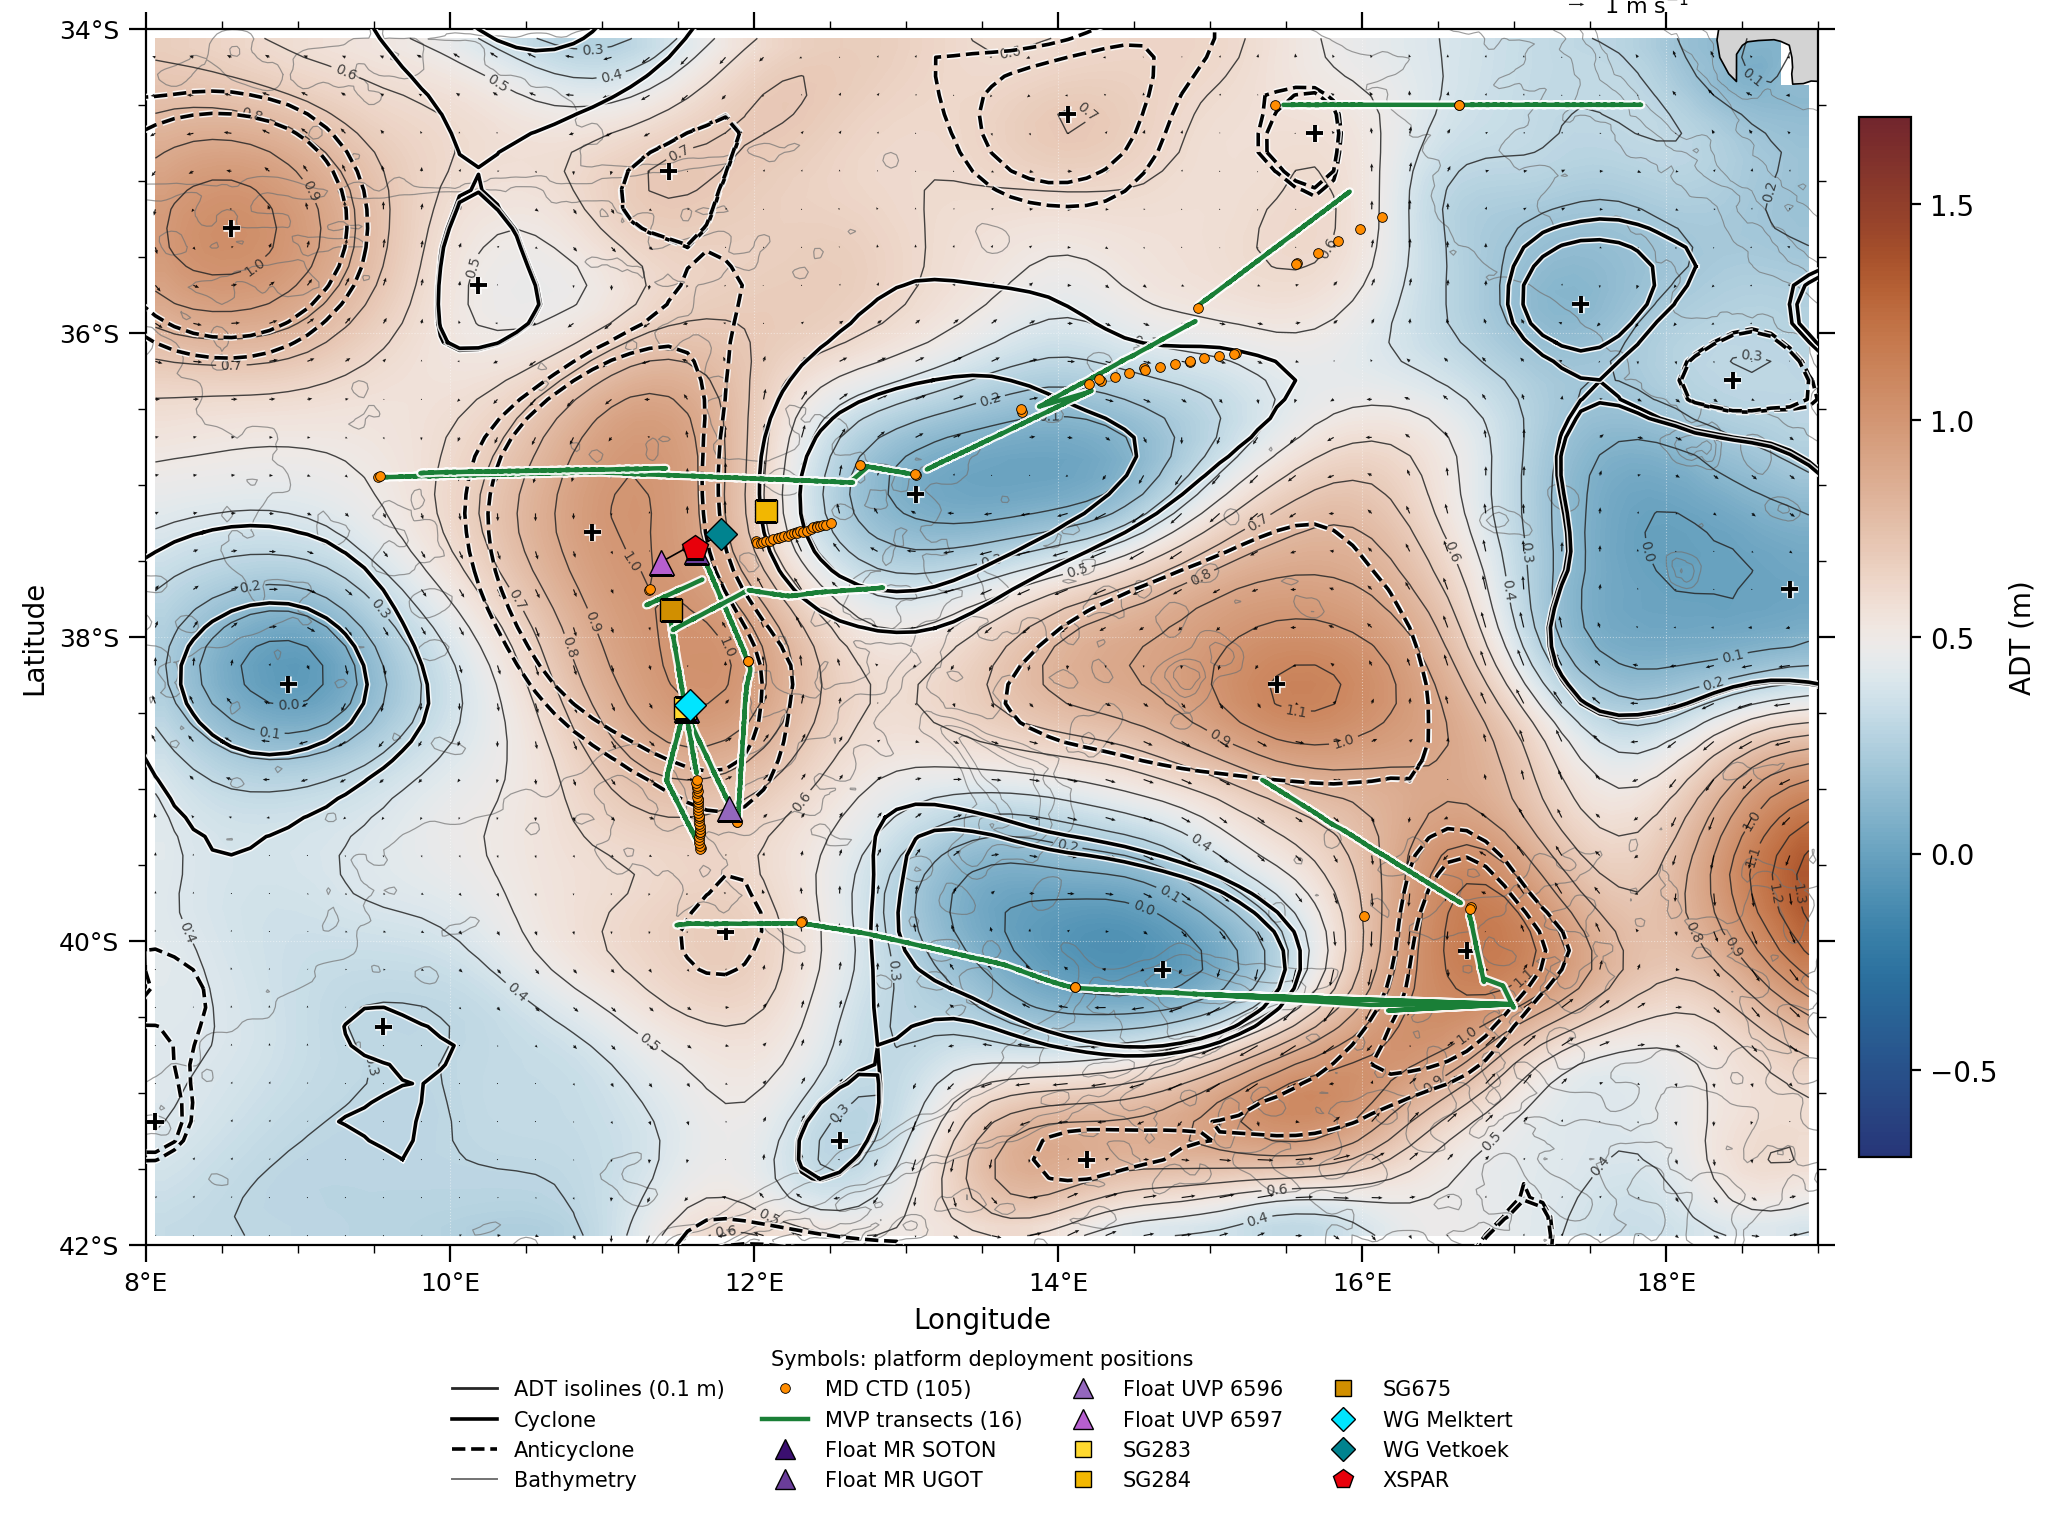

In [9]:
import re
import matplotlib.patheffects as pe
import matplotlib.transforms as mtransforms

# ---------------------------------------------------------------------------
# MVP transects -> one position per cast
# ---------------------------------------------------------------------------
sadcp = cascade_add_time(xr.open_dataset(SADCP_FILES[type_SADCP]))
sadcp = sadcp.sortby("time")
sadcp = sadcp.isel(time=~sadcp.indexes["time"].duplicated())

transect_names = sorted((f for f in mvp_files if f.startswith('transect ')),
                        key=lambda f: int(f.split()[-1]))
mvp_tracks = {}                # {transect_num: (lon_per_cast, lat_per_cast)}

for name in transect_names:
    transect_num = int(name.split()[-1])
    transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{name}/'
    files = sorted(Path(transect_path).glob("*.csv"))
    dfs = []
    for k, fcsv in enumerate(files):
        df = pd.read_csv(fcsv)
        df["CAST"] = k          # one processed CSV file = one MVP cast
        dfs.append(df)
    mvp_trans = pd.concat(dfs, ignore_index=True)

    if mvp_trans[["LON (°E)", "LAT (°N)"]].isna().any().any():
        sadcp_tr = sadcp_for_transect(mvp_trans, sadcp)
        sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min",
                                       keep=("LATITUDE", "LONGITUDE"))
        mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
        mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

    casts = (mvp_trans.assign(_t=pd.to_datetime(mvp_trans["TIME"]))
                      .groupby("CAST")
                      .agg(lon=("LON (°E)", "mean"), lat=("LAT (°N)", "mean"), t=("_t", "min"))
                      .dropna(subset=["lon", "lat"])
                      .sort_values("t"))
    mvp_tracks[transect_num] = (casts["lon"].values, casts["lat"].values)
    print(f"transect {transect_num}: {len(files)} files, {len(casts)} casts with a position")

# ---------------------------------------------------------------------------
# Deployment position = first fix in TIME of each platform file
# ---------------------------------------------------------------------------
def deployment(path):
    """(lon, lat, time) of the earliest valid fix in a track CSV, or None."""
    df = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig")
    df.columns = df.columns.str.strip().str.lower()
    lon_c = next((c for c in df.columns if c.startswith("lon")), None)
    lat_c = next((c for c in df.columns if c.startswith("lat")), None)
    if lon_c is None or lat_c is None:
        print(f"!! {Path(path).name}: columns are {list(df.columns)}")
        return None
    df["_lon"] = pd.to_numeric(df[lon_c], errors="coerce")
    df["_lat"] = pd.to_numeric(df[lat_c], errors="coerce")
    df = df.dropna(subset=["_lon", "_lat"])
    tcol = next((c for c in df.columns if "time" in c or "date" in c or c == "juld"), None)
    t0 = None
    if tcol is not None:
        t1 = pd.to_datetime(df[tcol], dayfirst=True, errors="coerce")
        t2 = pd.to_datetime(df[tcol], dayfirst=False, errors="coerce")
        df["_t"] = t1 if t1.notna().sum() >= t2.notna().sum() else t2
        df = df.dropna(subset=["_t"]).sort_values("_t")
        t0 = df["_t"].iloc[0] if len(df) else None
    else:
        print(f"!! {Path(path).name}: no time column -> first row used as deployment")
    if df.empty:
        return None
    return float(df["_lon"].iloc[0]), float(df["_lat"].iloc[0]), t0

def report(label, dep):
    lon, lat, t0 = dep
    print(f"{label:16s} deployed {t0:%Y-%m-%d %H:%M} at {lon:.3f}E {lat:.3f}N" if t0 is not None
          else f"{label:16s} deployed at {lon:.3f}E {lat:.3f}N (no time)")

# --- Floats ---
FLOAT_NAMES = {}               # optional overrides, e.g. {"mr_2.csv": "MR SOTON"}
FLOAT_COLORS = ["#3b0f70", "#6a3d9a", "#9467bd", "#b65fcf"]   # four shades of purple
DROP_WORDS = {"track", "tracks", "traj", "locations", "trajectory", "positions", "position", "data", "float"}

def float_label(fname):
    """'uvp_6596.csv' -> 'UVP 6596', 'mr_ugot_track.csv' -> 'MR UGOT'."""
    if fname in FLOAT_NAMES:
        return FLOAT_NAMES[fname]
    stem = Path(fname).stem
    prefix = "uvp" if stem.lower().startswith("uvp") else "mr"
    rest = re.split(r"[_\-\s.]+", stem[len(prefix):])
    rest = [w for w in rest if w and w.lower() not in DROP_WORDS]
    return " ".join([prefix.upper()] + [w.upper() for w in rest])

float_deploy = []              # [(label, lon, lat), ...]
for ff in sorted(os.listdir(DIR_FLOATS)):
    if not (ff.startswith('uvp') or ff.startswith('mr')) or not ff.endswith(".csv"):
        continue
    dep = deployment(DIR_FLOATS / ff)
    if dep:
        lab = f"Float {float_label(ff)}"
        float_deploy.append((lab, dep[0], dep[1]))
        report(lab, dep)

# --- Gliders (SGxxx, SeaExplorer = SGSE) ---
def glider_label(fname):
    """'sg283_track.csv' -> 'SG283', 'seaexplorer.csv' -> 'SGSE'."""
    stem = Path(fname).stem.lower()
    if "seaexplorer" in stem:
        return "SGSE"
    m = re.search(r"sg\s*_?(\d+)", stem)
    return f"SG{m.group(1)}" if m else Path(fname).stem.upper()

glider_deploy = []
for ff in sorted(f for f in os.listdir(DIR_SG) if f.lower().endswith(".csv")):
    dep = deployment(DIR_SG / ff)
    if dep:
        glider_deploy.append((glider_label(ff), dep[0], dep[1]))
        report(glider_label(ff), dep)
glider_deploy.sort(key=lambda g: (g[0] == "SGSE", g[0]))     # SG numbers first, SGSE last

# --- Wave gliders ---
WAVEGLIDER_FILES = [(DIR_WG / "melktert_track.csv", "WG Melktert"),
                    (DIR_WG / "vetkoek_track.csv",  "WG Vetkoek")]
wg_deploy = []
for path, label in WAVEGLIDER_FILES:
    if not path.exists():
        print(f"!! missing {path}")
        continue
    dep = deployment(path)
    if dep:
        wg_deploy.append((label, dep[0], dep[1]))
        report(label, dep)

# --- XSPAR ---
xspar_deploy = []
for ff in sorted(f for f in os.listdir(DIR_XSP) if f.lower().endswith(".csv")):
    dep = deployment(DIR_XSP / ff)
    if dep:
        xspar_deploy.append(("XSPAR", dep[0], dep[1]))
        report("XSPAR", dep)

# ---------------------------------------------------------------------------
# Map
# ---------------------------------------------------------------------------
LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = 8.0, 19.0, -42.0, -34.0
extent = (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX)

MVP_COLOR = "#1a7f37"
MVP_LW = 1.6
MVP_ZORDER = 7
MVP_LABELS = False
line_halo = [pe.Stroke(linewidth=MVP_LW + 1.6, foreground="white", alpha=0.9), pe.Normal()]

# Deployment markers (no tracks): one shape per platform type, shades within a type
FLOAT_MS, GLIDER_MS, WG_MS, XSPAR_MS = 9, 8, 8, 9.5
GLIDER_COLORS = ["#ffd92f", "#f2b701", "#d18f00", "#a86b00"]   # gold -> amber
WG_COLORS = ["#00e5ff", "#00838f"]                              # cyan / dark turquoise
XSPAR_COLOR = "#e8000b"                                         # red
DEPLOY_ZORDER = 1000

# Deployments that overlap: shift apart (points) with a leader line to the true position.
# Keys are the legend names.
DEPLOY_NUDGE = {"WG Vetkoek":     ( 9,  5),
                "Float UVP 6597": (-9, -5)}

def draw_deploy(ax, lon, lat, marker, ms, col, name):
    """Deployment marker; if `name` is in DEPLOY_NUDGE, draw it offset with a thin
    leader line and a small black dot at the real deployment position."""
    base = ccrs.PlateCarree()._as_mpl_transform(ax)
    dx, dy = DEPLOY_NUDGE.get(name, (0, 0))
    tr = base
    if dx or dy:
        tr = mtransforms.offset_copy(base, fig=ax.figure, x=dx, y=dy, units="points")
        ax.annotate("", xy=(lon, lat), xycoords=base, xytext=(dx, dy),
                    textcoords="offset points", zorder=DEPLOY_ZORDER - 1,
                    arrowprops=dict(arrowstyle="-", color="k", lw=0.6,
                                    shrinkA=0, shrinkB=0))
        ax.plot(lon, lat, "o", ms=2, color="k", transform=base, zorder=DEPLOY_ZORDER)
    ax.plot(lon, lat, marker, ms=ms, mfc=col, mec="k", mew=0.5, alpha=1,
            transform=tr, zorder=DEPLOY_ZORDER + 1)

LON, LAT, adt, ugos, vgos, date_stem = ssh_for_date(target)
eddies = eddies_for_date(date_stem)
md_ctd = load_ctd_positions_nc(MD_CTD_NC, label="MD CTD")
ag_ctd = load_ctd_positions_xlsx(find_agulhas_xlsx(), sheet=AGU_CTD_SHEET,
                                 dedupe_by_station=True, label="SA Agulhas CTD")
cmap = adt_colormap()

fig, ax = plt.subplots(figsize=FIG_SIZE_FULL, subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent(list(extent), crs=ccrs.PlateCarree())

img = ax.imshow(adt, extent=[LON.min(), LON.max(), LAT.min(), LAT.max()],
                cmap=cmap, origin="lower", vmin=ADT_VMIN, vmax=ADT_VMAX,
                alpha=0.85, transform=ccrs.PlateCarree(), zorder=1,
                interpolation="bilinear")
cb = fig.colorbar(img, ax=ax, shrink=0.75, pad=0.02)
cb.set_label("ADT (m)")

draw_currents(fig, ax, LON, LAT, ugos, vgos, is_zoom=False)
draw_adt_isolines(ax, LON, LAT, adt)
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray", zorder=2)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.6, zorder=3)
draw_bathymetry(ax, extent)
draw_eddies(ax, eddies)
draw_ctds(ax, md_ctd, ag_ctd)

# --- MVP transects ---
for num, (lo, la) in mvp_tracks.items():
    ok = np.isfinite(lo) & np.isfinite(la)
    lo, la = lo[ok], la[ok]
    if lo.size == 0:
        continue
    ax.plot(lo, la, "-", color=MVP_COLOR, lw=MVP_LW, solid_capstyle="round",
            zorder=MVP_ZORDER, path_effects=line_halo, transform=ccrs.PlateCarree())
    if MVP_LABELS:
        ax.text(lo[0], la[0], f" {num}", fontsize=6, fontweight="bold", color=MVP_COLOR,
                ha="left", va="bottom", zorder=MVP_ZORDER + 1, transform=ccrs.PlateCarree(),
                path_effects=[pe.withStroke(linewidth=1.8, foreground="white")])

# --- Deployment positions only ---
for (lab, lon, lat), col in zip(float_deploy, FLOAT_COLORS):
    draw_deploy(ax, lon, lat, "^", FLOAT_MS, col, lab)
for (lab, lon, lat), col in zip(glider_deploy, GLIDER_COLORS):
    draw_deploy(ax, lon, lat, "s", GLIDER_MS, col, lab)
for (lab, lon, lat), col in zip(wg_deploy, WG_COLORS):
    draw_deploy(ax, lon, lat, "D", WG_MS, col, lab)
for (lab, lon, lat) in xspar_deploy:
    draw_deploy(ax, lon, lat, "p", XSPAR_MS, XSPAR_COLOR, lab)

setup_ticks(ax, extent)
ax.set_extent(list(extent), crs=ccrs.PlateCarree())   # ticks must not widen the map

# --- Legend: below the map, in columns ---
def marker_handle(marker, ms, col, label):
    return mlines.Line2D([], [], ls="None", marker=marker, ms=ms, mfc=col, mec="k",
                         mew=0.5, label=label)

handles = [
    mlines.Line2D([], [], color=ADT_ISO_COLOR, ls="-", lw=ADT_ISO_LW * 2,
                  label=f"ADT isolines ({ADT_ISO_STEP:g} m)"),
    mlines.Line2D([], [], color=EDDY_COLOR, ls="-", lw=EDDY_LW, label="Cyclone"),
    mlines.Line2D([], [], color=EDDY_COLOR, ls="--", lw=EDDY_LW, label="Anticyclone"),
    mlines.Line2D([], [], color=BATHY_COLOR, ls="-", lw=BATHY_LW * 2, label="Bathymetry"),
]
if md_ctd[0].size:
    handles.append(mlines.Line2D([], [], color=MD_CTD_COLOR, ls="None", marker="o",
                                 ms=CTD_MS, mec=CTD_MEC, mew=CTD_MEW,
                                 label=f"MD CTD ({md_ctd[0].size})"))
if ag_ctd[0].size:
    handles.append(mlines.Line2D([], [], color=AGU_CTD_COLOR, ls="None", marker="o",
                                 ms=CTD_MS, mec=CTD_MEC, mew=CTD_MEW,
                                 label=f"SA Agulhas CTD ({ag_ctd[0].size})"))
if mvp_tracks:
    handles.append(mlines.Line2D([], [], color=MVP_COLOR, lw=MVP_LW, path_effects=line_halo,
                                 label=f"MVP transects ({len(mvp_tracks)})"))
handles += [marker_handle("^", FLOAT_MS - 2, c, lab) for (lab, _, _), c in zip(float_deploy, FLOAT_COLORS)]
handles += [marker_handle("s", GLIDER_MS - 2, c, lab) for (lab, _, _), c in zip(glider_deploy, GLIDER_COLORS)]
handles += [marker_handle("D", WG_MS - 2, c, lab) for (lab, _, _), c in zip(wg_deploy, WG_COLORS)]
handles += [marker_handle("p", XSPAR_MS - 2, XSPAR_COLOR, lab) for (lab, _, _) in xspar_deploy]

ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.07),
          ncol=4, fontsize=7.5, frameon=False, columnspacing=1.8, handlelength=2.2,
          title="Symbols: platform deployment positions", title_fontsize=7.5)

# ax.set_title(f"WHIRLS sampling: CTD, MVP and platform deployments  -  ADT {date_stem}",
#              loc="left", fontsize=10)

OUT_DIR.mkdir(parents=True, exist_ok=True)
out = OUT_DIR / f"{date_stem}_WHIRLS_adt_ctd_mvp_deployments.png"
fig.savefig(out, dpi=FIG_DPI, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

transect 1: 66 files, 65 casts with a position
transect 2: 90 files, 90 casts with a position
transect 3: 26 files, 26 casts with a position
transect 4: 42 files, 42 casts with a position
transect 5: 56 files, 56 casts with a position
transect 6: 24 files, 24 casts with a position
transect 7: 52 files, 52 casts with a position
transect 8: 20 files, 20 casts with a position
transect 9: 52 files, 52 casts with a position
transect 10: 104 files, 104 casts with a position
transect 11: 16 files, 16 casts with a position
transect 12: 118 files, 118 casts with a position
transect 13: 60 files, 60 casts with a position
transect 14: 100 files, 100 casts with a position
transect 15: 118 files, 118 casts with a position
transect 16: 68 files, 68 casts with a position
'mr_float_soton_positions.csv' -> 'Float MR SOTON': 326 positions
'mr_float_ugot_positions.csv' -> 'Float MR UGOT': 322 positions
'uvp_float_6596_locations.csv' -> 'Float UVP 6596': 25 positions
'uvp_float_6597_locations.csv' -> 'Flo

/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_36178/1128587283.py:100: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dff[tcol] = pd.to_datetime(dff[tcol], dayfirst=True, errors="coerce")


MD CTD: positions from variables 'lat_start' / 'lon_start'
MD CTD: 105 CTD positions from /Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/CTD/ctd_metadata.nc; dates 2026-06-29 .. 2026-07-26
[info] no SA Agulhas CTD file (Agu*.xlsx) under data/CTD; Agulhas CTDs not drawn. Set AGU_CTD_XLSX if you have it elsewhere.
[info] ADT colormap: Crameri 'vik'
ADT isolines: 18 levels, -0.1 .. 1.6 m, step 0.1 m
ADT isolines: 18 levels, -0.1 .. 1.6 m, step 0.1 m
Saved /Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/2026-07-13_WHIRLS_platforms_and_drifters.png


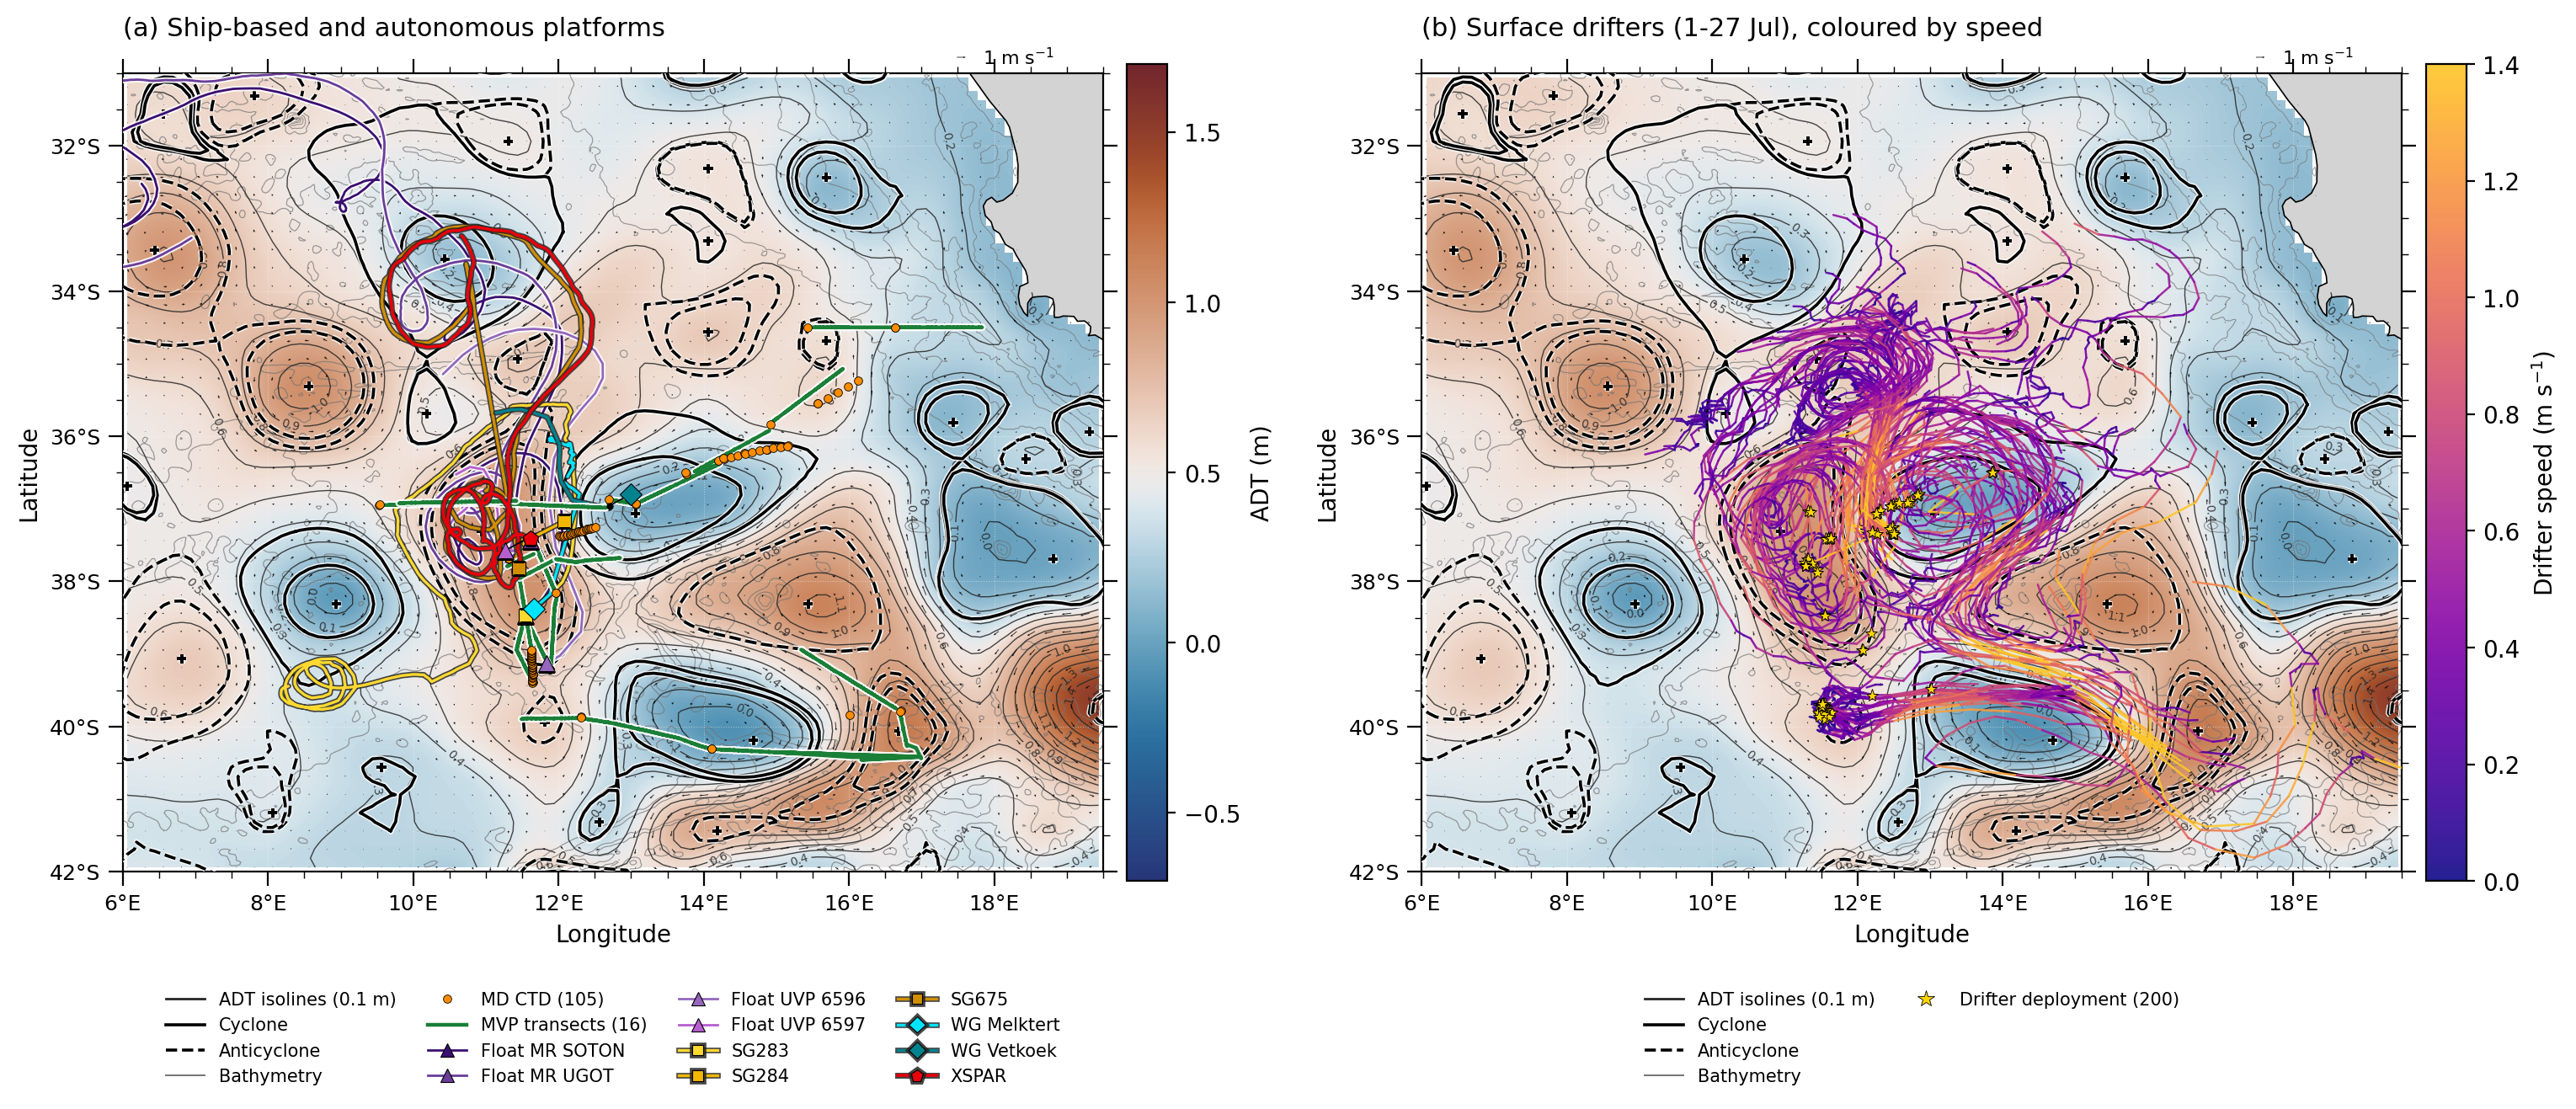

In [14]:
import re
import json
import matplotlib.patheffects as pe
import matplotlib.transforms as mtransforms
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# ---------------------------------------------------------------------------
# MVP transects -> one position per cast
# ---------------------------------------------------------------------------
sadcp = cascade_add_time(xr.open_dataset(SADCP_FILES[type_SADCP]))
sadcp = sadcp.sortby("time")
sadcp = sadcp.isel(time=~sadcp.indexes["time"].duplicated())

transect_names = sorted((f for f in mvp_files if f.startswith('transect ')),
                        key=lambda f: int(f.split()[-1]))
mvp_tracks = {}                # {transect_num: (lon_per_cast, lat_per_cast)}

for name in transect_names:
    transect_num = int(name.split()[-1])
    transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{name}/'
    files = sorted(Path(transect_path).glob("*.csv"))
    dfs = []
    for k, fcsv in enumerate(files):
        df = pd.read_csv(fcsv)
        df["CAST"] = k          # one processed CSV file = one MVP cast
        dfs.append(df)
    mvp_trans = pd.concat(dfs, ignore_index=True)

    if mvp_trans[["LON (°E)", "LAT (°N)"]].isna().any().any():
        sadcp_tr = sadcp_for_transect(mvp_trans, sadcp)
        sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min",
                                       keep=("LATITUDE", "LONGITUDE"))
        mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
        mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

    casts = (mvp_trans.assign(_t=pd.to_datetime(mvp_trans["TIME"]))
                      .groupby("CAST")
                      .agg(lon=("LON (°E)", "mean"), lat=("LAT (°N)", "mean"), t=("_t", "min"))
                      .dropna(subset=["lon", "lat"])
                      .sort_values("t"))
    mvp_tracks[transect_num] = (casts["lon"].values, casts["lat"].values)
    print(f"transect {transect_num}: {len(files)} files, {len(casts)} casts with a position")

# ---------------------------------------------------------------------------
# Floats -> one named track per file
# ---------------------------------------------------------------------------
FLOAT_NAMES = {}               # optional overrides, e.g. {"mr_2.csv": "MR SOTON"}
FLOAT_COLORS = ["#3b0f70", "#6a3d9a", "#9467bd", "#b65fcf"]   # four shades of purple
DROP_WORDS = {"track", "tracks", "traj", "locations", "trajectory", "positions", "position", "data", "float"}

def float_label(fname):
    """'uvp_6596.csv' -> 'UVP 6596', 'mr_ugot_track.csv' -> 'MR UGOT'."""
    if fname in FLOAT_NAMES:
        return FLOAT_NAMES[fname]
    stem = Path(fname).stem
    prefix = "uvp" if stem.lower().startswith("uvp") else "mr"
    rest = re.split(r"[_\-\s.]+", stem[len(prefix):])
    rest = [w for w in rest if w and w.lower() not in DROP_WORDS]
    return " ".join([prefix.upper()] + [w.upper() for w in rest])

float_tracks = []              # [(label, lon, lat), ...]
for ff in sorted(os.listdir(DIR_FLOATS)):
    if not (ff.startswith('uvp') or ff.startswith('mr')) or not ff.endswith(".csv"):
        continue
    dff = pd.read_csv(DIR_FLOATS / ff)
    tcol = next((c for c in dff.columns if c.lower() in ("time", "date", "datetime", "juld")), None)
    if tcol is not None:
        dff = dff.assign(_t=pd.to_datetime(dff[tcol], errors="coerce")).sort_values("_t")
    lon_float = pd.to_numeric(dff['longitude'], errors="coerce").values
    lat_float = pd.to_numeric(dff['latitude'], errors="coerce").values
    ok = np.isfinite(lon_float) & np.isfinite(lat_float)
    if ok.any():
        float_tracks.append((float_label(ff), lon_float[ok], lat_float[ok]))
        print(f"'{ff}' -> 'Float {float_label(ff)}': {ok.sum()} positions")

# ---------------------------------------------------------------------------
# Gliders -> one named track per file (SGxxx, SeaExplorer = SGSE)
# ---------------------------------------------------------------------------
def glider_label(fname):
    """'sg283_track.csv' -> 'SG283', 'seaexplorer.csv' -> 'SGSE'."""
    stem = Path(fname).stem.lower()
    if "seaexplorer" in stem:
        return "SGSE"
    m = re.search(r"sg\s*_?(\d+)", stem)
    return f"SG{m.group(1)}" if m else Path(fname).stem.upper()

glider_files = sorted(f for f in os.listdir(DIR_SG) if f.endswith(".csv"))
glider_tracks = []             # [(label, lon, lat), ...]
for ff in glider_files:
    dff = pd.read_csv(DIR_SG / ff, sep=None, engine="python", encoding="utf-8-sig")
    dff.columns = dff.columns.str.strip().str.lower()
    tcol = next((c for c in dff.columns if c in ("time", "date", "datetime", "timestamp")), None)
    lon_c = next((c for c in dff.columns if c.startswith("lon")), None)
    lat_c = next((c for c in dff.columns if c.startswith("lat")), None)
    if lon_c is None or lat_c is None:
        print(f"!! {ff}: columns are {list(dff.columns)}")
        continue
    if tcol is not None:
        dff[tcol] = pd.to_datetime(dff[tcol], dayfirst=True, errors="coerce")
        dff = dff.sort_values(tcol)
    lon_glider = pd.to_numeric(dff[lon_c], errors="coerce").values
    lat_glider = pd.to_numeric(dff[lat_c], errors="coerce").values
    ok = np.isfinite(lon_glider) & np.isfinite(lat_glider)
    if ok.any():
        glider_tracks.append((glider_label(ff), lon_glider[ok], lat_glider[ok]))
        print(f"'{ff}' -> '{glider_label(ff)}': {ok.sum()} positions")
glider_tracks.sort(key=lambda g: (g[0] == "SGSE", g[0]))

# ---------------------------------------------------------------------------
# Wave gliders -> one named track per file
# ---------------------------------------------------------------------------
WAVEGLIDER_FILES = [(DIR_WG / "melktert_track.csv", "WG Melktert"),
                    (DIR_WG / "vetkoek_track.csv",  "WG Vetkoek")]
# Wave gliders move at < ~1 m/s; fixes taken on the ship (recovery, transit to/from
# Cape Town) move much faster. The track is split into its in-water pieces
# (one per deployment) and WG_KEEP chooses which to draw.
WG_SHIP_SPEED = 1.5            # m/s over WG_SPEED_WINDOW_H: faster = on the ship
WG_SPEED_WINDOW_H = 1.0        # speed measured over ~1 h (GPS noise between close fixes doesn't count)
WG_MIN_PIECE_H = 12            # in-water pieces shorter than this are ignored
WG_KEEP_DEFAULT = "all"        # "all" deployments, "last" deployment, or "longest"
WG_KEEP = {"WG Vetkoek": "last"}   # Vetkoek: only the last deployment (the filament, 17-22 Jul)
WG_WINDOWS = {}                # manual override, e.g. {"WG Melktert": ("2026-07-03", "2026-07-20")}

def parse_time(col):
    """Datetime from strings (day-first or month-first) or Unix epoch numbers (s or ms)."""
    num = pd.to_numeric(col, errors="coerce")
    if num.notna().mean() > 0.9:
        return pd.to_datetime(num, unit="ms" if num.median() > 1e11 else "s", errors="coerce")
    t1 = pd.to_datetime(col, dayfirst=True, errors="coerce")
    t2 = pd.to_datetime(col, dayfirst=False, errors="coerce")
    return t1 if t1.notna().sum() >= t2.notna().sum() else t2

def in_water_pieces(t, lo, la, max_speed=WG_SHIP_SPEED, window_h=WG_SPEED_WINDOW_H,
                    min_piece_h=WG_MIN_PIECE_H):
    """(i0, i1) index ranges where the platform moves slower than max_speed
    (speed to the first fix >= window_h later), each lasting >= min_piece_h."""
    n = len(lo)
    ts = t.astype("datetime64[s]").astype(float)
    j = np.minimum(np.searchsorted(ts, ts + window_h * 3600), n - 1)
    dt = ts[j] - ts
    dx = np.deg2rad(lo[j] - lo) * np.cos(np.deg2rad(0.5 * (la[j] + la)))
    d = 6371e3 * np.hypot(dx, np.deg2rad(la[j] - la))
    with np.errstate(divide="ignore", invalid="ignore"):
        spd = pd.Series(np.where(dt > 0, d / dt, np.nan)).ffill().bfill().values
    slow = spd <= max_speed
    pieces, start = [], None
    for k in range(n + 1):
        if k < n and slow[k]:
            start = k if start is None else start
        elif start is not None:
            if (ts[k - 1] - ts[start]) / 3600 >= min_piece_h:
                pieces.append((start, k))
            start = None
    return pieces

wg_tracks = []                 # [(label, lon, lat), ...]  (NaN between deployments)
for path, label in WAVEGLIDER_FILES:
    if not path.exists():
        print(f"!! missing {path}")
        continue
    dfw = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig")
    dfw.columns = dfw.columns.str.strip().str.lower()
    tcol = next((c for c in dfw.columns if "time" in c or "date" in c), None)
    lon_c = next((c for c in dfw.columns if c.startswith("lon")), None)
    lat_c = next((c for c in dfw.columns if c.startswith("lat")), None)
    if lon_c is None or lat_c is None or tcol is None:
        print(f"!! {path.name}: columns are {list(dfw.columns)}")
        continue
    dfw["_t"] = parse_time(dfw[tcol])
    dfw["_lon"] = pd.to_numeric(dfw[lon_c], errors="coerce")
    dfw["_lat"] = pd.to_numeric(dfw[lat_c], errors="coerce")
    dfw = (dfw.dropna(subset=["_t", "_lon", "_lat"]).sort_values("_t")
              .drop_duplicates(subset=["_t"]))
    if label in WG_WINDOWS:
        t0, t1 = WG_WINDOWS[label]
        dfw = dfw[(dfw["_t"] >= pd.Timestamp(t0)) & (dfw["_t"] <= pd.Timestamp(t1))]
    tt, lo, la = dfw["_t"].values, dfw["_lon"].values, dfw["_lat"].values
    if lo.size == 0:
        continue

    if label not in WG_WINDOWS:
        pieces = in_water_pieces(tt, lo, la)
        for i0, i1 in pieces:
            print(f"   {label} in water {pd.Timestamp(tt[i0]):%d %b %H:%M} -> "
                  f"{pd.Timestamp(tt[i1-1]):%d %b %H:%M} ({i1 - i0} fixes)")
        keep = WG_KEEP.get(label, WG_KEEP_DEFAULT)
        if not pieces:
            print(f"!! {label}: no in-water piece found -> whole track kept")
            pieces = [(0, lo.size)]
        elif keep == "last":
            pieces = pieces[-1:]
        elif keep == "longest":
            pieces = [max(pieces, key=lambda r: r[1] - r[0])]
        # join the kept pieces with NaN breaks (no line across ship legs)
        lo = np.concatenate([np.r_[lo[a:b], np.nan] for a, b in pieces])[:-1]
        la = np.concatenate([np.r_[la[a:b], np.nan] for a, b in pieces])[:-1]
        print(f"'{path.name}' -> '{label}': drawing {keep} "
              f"({len(pieces)} piece{'s' if len(pieces) > 1 else ''})")
    wg_tracks.append((label, lo, la))

# ---------------------------------------------------------------------------
# XSPAR -> one track, sorted in time, no straight jumps
# ---------------------------------------------------------------------------
XSPAR_MAX_GAP_KM = 30

def break_long_jumps(lo, la, max_km):
    """Insert NaN between consecutive fixes more than max_km apart."""
    dx = np.deg2rad(np.diff(lo)) * np.cos(np.deg2rad(0.5 * (la[1:] + la[:-1])))
    d = 6371.0 * np.hypot(dx, np.deg2rad(np.diff(la)))
    cut = np.flatnonzero(d > max_km) + 1
    return np.insert(lo, cut, np.nan), np.insert(la, cut, np.nan), len(cut)

xspar_tracks = []              # [(label, lon, lat), ...]
for ff in sorted(f for f in os.listdir(DIR_XSP) if f.lower().endswith(".csv")):
    dfx = pd.read_csv(DIR_XSP / ff, sep=None, engine="python", encoding="utf-8-sig")
    dfx.columns = dfx.columns.str.strip().str.lower()
    tcol = next((c for c in dfx.columns if "time" in c or "date" in c), None)
    lon_c = next((c for c in dfx.columns if c.startswith("lon")), None)
    lat_c = next((c for c in dfx.columns if c.startswith("lat")), None)
    if lon_c is None or lat_c is None:
        print(f"!! {ff}: no lon/lat column")
        continue
    if tcol is not None:
        t1 = pd.to_datetime(dfx[tcol], dayfirst=True, errors="coerce")
        t2 = pd.to_datetime(dfx[tcol], dayfirst=False, errors="coerce")
        dfx["_t"] = t1 if t1.notna().sum() >= t2.notna().sum() else t2
        dfx = dfx.dropna(subset=["_t"]).sort_values("_t").drop_duplicates("_t")
    lo = pd.to_numeric(dfx[lon_c], errors="coerce").values
    la = pd.to_numeric(dfx[lat_c], errors="coerce").values
    ok = np.isfinite(lo) & np.isfinite(la)
    lo, la = lo[ok], la[ok]
    if lo.size:
        lo_b, la_b, n_cut = break_long_jumps(lo, la, XSPAR_MAX_GAP_KM)
        xspar_tracks.append(("XSPAR", lo_b, la_b))
        print(f"'{ff}' -> 'XSPAR': {lo.size} positions, line broken at {n_cut} jumps")

# ---------------------------------------------------------------------------
# Drifters: read from drifters_tracks.geojson (functions from drifters.ipynb)
# ---------------------------------------------------------------------------
DRIFT_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"
FIRST_LAUNCH = "2026-07-01 05:00"     # fixes before this are bench tests / on deck
DRIFTER_END = "2026-07-27"            # last fix drawn (cruise end); None = whole record
DRIFT_CACHE = OUT_DIR / "drifters_clean_geojson.csv"   # delete to re-read the geojson
MAX_DT_H = 13.0                       # geojson fixes are ~10.6 h apart; no segment across longer gaps
MAX_SPEED = 3.0                       # m/s: faster segments are on-deck legs / GPS spikes
SPEED_SMOOTH_N = 1                    # running mean over this many fixes (1 = raw; fixes are already 10 h apart)
SPEED_LIM = None                      # (vmin, vmax) m/s; None = 0 .. 98th percentile
from matplotlib.colors import LinearSegmentedColormap
# plasma (dark blue-purple -> magenta -> orange), palest end cut so slow drifters stay visible
SPEED_CMAP = LinearSegmentedColormap.from_list(
    "plasma_trunc", plt.get_cmap("plasma")(np.linspace(0.0, 0.88, 256)))

def _dist_m(lon1, lat1, lon2, lat2):
    R = 6371e3
    lon1, lat1, lon2, lat2 = map(np.deg2rad, (lon1, lat1, lon2, lat2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(a))

def _add_speed(df):
    """Speed (m/s) and gap (h) from each fix to the NEXT fix of the same drifter."""
    g = df.groupby("id")
    lon2, lat2, t2 = g["lon"].shift(-1), g["lat"].shift(-1), g["time"].shift(-1)
    df["dt_h"] = (t2 - df["time"]).dt.total_seconds() / 3600
    df["speed"] = _dist_m(df["lon"], df["lat"], lon2, lat2) / (df["dt_h"] * 3600)
    return df

def read_drifter_geojson(path):
    """
    The geojson has, per drifter (D_number):
      kind='track'           : one LineString with all positions, NO times
      kind='track_segment'   : 2-point LineStrings, start_date -> end_date
      kind='latest_position' : one Point
    Times only live on the segments, so fixes are rebuilt from them.
    The 'speed_mps' property is unreliable (up to 553 m/s), so speeds are
    recomputed from the positions (_add_speed).
    Returns DataFrame [id, time, lon, lat] sorted by id, time.
    """
    with open(path) as f:
        feats = json.load(f)["features"]
    rows = []
    for ft in feats:
        p = ft["properties"]
        if p.get("kind") != "track_segment":
            continue
        (lon0, lat0), (lon1, lat1) = [c[:2] for c in ft["geometry"]["coordinates"]]
        rows.append((p["D_number"], p["start_date"], lon0, lat0))
        rows.append((p["D_number"], p["end_date"], lon1, lat1))
    df = pd.DataFrame(rows, columns=["id", "time", "lon", "lat"])
    df["time"] = pd.to_datetime(df["time"], utc=True).dt.tz_localize(None)
    return (df.drop_duplicates(["id", "time"])
              .sort_values(["id", "time"]).reset_index(drop=True))

def clean_drifters(df, max_deploy_speed=1.5, max_gap_days=2, spike_speed=3.0,
                   match_hours=6, match_km=25):
    """Drop on-deck fixes before each drifter's deployment, then GPS spikes."""
    df = _add_speed(df.copy())
    clear = (df["speed"] < max_deploy_speed) & (df["dt_h"] < max_gap_days * 24)
    first = df.groupby("id").head(1)
    first = first[clear.loc[first.index]].sort_values("time")
    events = []
    for _, r in first.iterrows():
        for e in events:
            if (abs((r.time - e[0]).total_seconds()) < match_hours * 3600
                    and _dist_m(r.lon, r.lat, e[1], e[2]) < match_km * 1e3):
                e[3] += 1
                break
        else:
            events.append([r.time, r.lon, r.lat, 1])
    ev = pd.DataFrame(events, columns=["time", "lon", "lat", "n"])

    def near_event(r):
        dt = (ev["time"] - r.time).abs().dt.total_seconds()
        d = _dist_m(r.lon, r.lat, ev["lon"].values, ev["lat"].values)
        m = (dt < match_hours * 3600) & (d < match_km * 1e3)
        return ev.loc[m, "time"].iloc[0] if m.any() else pd.NaT

    keep = []
    for did, g in df.groupby("id", sort=False):
        start, launch = None, pd.NaT
        for i, (idx, r) in enumerate(g.iterrows()):
            launch = near_event(r)
            if pd.notna(launch) or clear[idx]:
                start = i
                break
        if start is None:
            continue
        g = g.iloc[start:].copy()
        g["launch"] = launch if pd.notna(launch) else g["time"].iloc[0]
        keep.append(g)
    df = pd.concat(keep).reset_index(drop=True)
    for _ in range(3):
        df = _add_speed(df)
        speed_in = df.groupby("id")["speed"].shift(1)
        spike = (df["speed"] > spike_speed) & (speed_in > spike_speed)
        if not spike.any():
            break
        df = df[~spike].reset_index(drop=True)
    return _add_speed(df)

if DRIFT_CACHE.exists():
    drift = pd.read_csv(DRIFT_CACHE, parse_dates=["time"])
    print(f"drifters: from cache {DRIFT_CACHE.name}")
else:
    raw = read_drifter_geojson(DRIFT_GEOJSON)
    raw = raw[raw["time"] >= pd.Timestamp(FIRST_LAUNCH)]
    drift = clean_drifters(raw)
    print(f"{raw['id'].nunique()} drifters, {len(raw)} fixes -> {len(drift)} after "
          "removing on-deck fixes and spikes")
    drift[["id", "time", "lon", "lat"]].to_csv(DRIFT_CACHE, index=False)

drift = drift.sort_values(["id", "time"]).reset_index(drop=True)
if DRIFTER_END:
    drift = drift[drift["time"] <= pd.Timestamp(DRIFTER_END) + pd.Timedelta("1D")]
drift = _add_speed(drift.reset_index(drop=True))
print(f"drifters: {drift['id'].nunique()}, fixes every ~{drift['dt_h'].median():.1f} h")

# segments between consecutive fixes, coloured by speed
segs, seg_speed, drift_deploy = [], [], []
for did, g in drift.groupby("id"):
    lon_d, lat_d = g["lon"].values, g["lat"].values
    drift_deploy.append((lon_d[0], lat_d[0]))
    if len(g) < 2:
        continue
    spd = g["speed"].values.astype(float)            # speed to the next fix (from positions)
    if SPEED_SMOOTH_N > 1:
        spd = pd.Series(spd).rolling(SPEED_SMOOTH_N, center=True, min_periods=1).mean().values
    dt_h = g["dt_h"].values[:-1]
    ok = (dt_h > 0) & (dt_h <= MAX_DT_H) & np.isfinite(spd[:-1]) & (g["speed"].values[:-1] < MAX_SPEED)
    s = np.stack([np.c_[lon_d[:-1], lat_d[:-1]], np.c_[lon_d[1:], lat_d[1:]]], axis=1)
    segs.append(s[ok])
    seg_speed.append(spd[:-1][ok])
segs = np.concatenate(segs) if segs else np.empty((0, 2, 2))
seg_speed = np.concatenate(seg_speed) if seg_speed else np.empty(0)
drift_deploy = np.array(drift_deploy)

# ---------------------------------------------------------------------------
# Map settings
# ---------------------------------------------------------------------------
MVP_COLOR = "#1a7f37"
MVP_LW = 1.6
MVP_ZORDER = 7
MVP_LABELS = False
line_halo = [pe.Stroke(linewidth=MVP_LW + 1.6, foreground="white", alpha=0.9), pe.Normal()]

FLOAT_LW = 1.0
FLOAT_MS = 7.5
FLOAT_ZORDER = 6.5
float_halo = [pe.Stroke(linewidth=FLOAT_LW + 1.4, foreground="white", alpha=0.9), pe.Normal()]

GLIDER_COLORS = ["#ffd92f", "#f2b701", "#d18f00", "#a86b00"]
GLIDER_LW = 1.2
GLIDER_MS = 6
GLIDER_ZORDER = 6.8
glider_halo = [pe.Stroke(linewidth=GLIDER_LW + 1.2, foreground="0.15", alpha=0.85), pe.Normal()]

WG_COLORS = ["#00e5ff", "#00838f"]
WG_LW = 1.2
WG_MS = 6.5
WG_ZORDER = 6.9
wg_halo = [pe.Stroke(linewidth=WG_LW + 1.2, foreground="0.15", alpha=0.85), pe.Normal()]

XSPAR_COLOR = "#e8000b"
XSPAR_LW = 1.3
XSPAR_MS = 7
XSPAR_ZORDER = 7.1
xspar_halo = [pe.Stroke(linewidth=XSPAR_LW + 1.2, foreground="0.15", alpha=0.85), pe.Normal()]

DRIFT_LW = 0.9                 # thin: 200 tracks
DRIFT_ALPHA = 0.9
DRIFT_DEPLOY_MS = 5.5
DRIFT_DEPLOY_COLOR = "#ffd700"
DEPLOY_ZORDER = 1000

DEPLOY_NUDGE = {"WG Vetkoek":     ( 9,  5),
                "Float UVP 6597": (-9, -5)}

def draw_deploy(ax, lon, lat, marker, ms, col, name):
    base = ccrs.PlateCarree()._as_mpl_transform(ax)
    dx, dy = DEPLOY_NUDGE.get(name, (0, 0))
    tr = base
    if dx or dy:
        tr = mtransforms.offset_copy(base, fig=ax.figure, x=dx, y=dy, units="points")
        ax.annotate("", xy=(lon, lat), xycoords=base, xytext=(dx, dy),
                    textcoords="offset points", zorder=DEPLOY_ZORDER - 1,
                    arrowprops=dict(arrowstyle="-", color="k", lw=0.6, shrinkA=0, shrinkB=0))
        ax.plot(lon, lat, "o", ms=2, color="k", transform=base, zorder=DEPLOY_ZORDER)
    ax.plot(lon, lat, marker, ms=ms, mfc=col, mec="k", mew=0.4, alpha=1,
            transform=tr, zorder=DEPLOY_ZORDER + 1)

# Map area (both panels). Floats reach 6E / 31S; nothing of interest east of ~19.5E
LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = 6.0, 19.5, -42.0, -31.0
extent = (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX)
EDDY_CENTER_MS = 4             # smaller TOEddies centre crosses (used by draw_eddies)

LON, LAT, adt, ugos, vgos, date_stem = ssh_for_date(target)
eddies = eddies_for_date(date_stem)
md_ctd = load_ctd_positions_nc(MD_CTD_NC, label="MD CTD")
ag_ctd = load_ctd_positions_xlsx(find_agulhas_xlsx(), sheet=AGU_CTD_SHEET,
                                 dedupe_by_station=True, label="SA Agulhas CTD")
cmap = adt_colormap()

fig = plt.figure(figsize=(19, 8.4))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
axd = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
fig.subplots_adjust(wspace=0.10)

# ======================= (a) LEFT: ADT + all platforms =======================
ax.set_extent(list(extent), crs=ccrs.PlateCarree())
img = ax.imshow(adt, extent=[LON.min(), LON.max(), LAT.min(), LAT.max()],
                cmap=cmap, origin="lower", vmin=ADT_VMIN, vmax=ADT_VMAX,
                alpha=0.85, transform=ccrs.PlateCarree(), zorder=1,
                interpolation="bilinear")
cb = fig.colorbar(img, ax=ax, shrink=0.75, pad=0.02)
cb.set_label("ADT (m)")

draw_currents(fig, ax, LON, LAT, ugos, vgos, is_zoom=False)
draw_adt_isolines(ax, LON, LAT, adt)
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray", zorder=2)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.6, zorder=3)
draw_bathymetry(ax, extent)
draw_eddies(ax, eddies)
draw_ctds(ax, md_ctd, ag_ctd)

for (flabel, lo, la), col in zip(float_tracks, FLOAT_COLORS):
    ax.plot(lo, la, "-", color=col, lw=FLOAT_LW, solid_capstyle="round",
            zorder=FLOAT_ZORDER, path_effects=float_halo, transform=ccrs.PlateCarree())
    draw_deploy(ax, lo[0], la[0], "^", FLOAT_MS, col, f"Float {flabel}")
for (glabel, lo, la), col in zip(glider_tracks, GLIDER_COLORS):
    ax.plot(lo, la, "-", color=col, lw=GLIDER_LW, solid_capstyle="round",
            zorder=GLIDER_ZORDER, path_effects=glider_halo, transform=ccrs.PlateCarree())
    draw_deploy(ax, lo[0], la[0], "s", GLIDER_MS, col, glabel)
for (wlabel, lo, la), col in zip(wg_tracks, WG_COLORS):
    ax.plot(lo, la, "-", color=col, lw=WG_LW, solid_capstyle="round",
            zorder=WG_ZORDER, path_effects=wg_halo, transform=ccrs.PlateCarree())
    i0 = np.flatnonzero(np.isfinite(lo))[0]
    draw_deploy(ax, lo[i0], la[i0], "D", WG_MS, col, wlabel)
for (xlabel, lo, la) in xspar_tracks:
    ax.plot(lo, la, "-", color=XSPAR_COLOR, lw=XSPAR_LW, solid_capstyle="round",
            zorder=XSPAR_ZORDER, path_effects=xspar_halo, transform=ccrs.PlateCarree())
    i0 = np.flatnonzero(np.isfinite(lo))[0]
    draw_deploy(ax, lo[i0], la[i0], "p", XSPAR_MS, XSPAR_COLOR, xlabel)
for num, (lo, la) in mvp_tracks.items():
    ok = np.isfinite(lo) & np.isfinite(la)
    if ok.any():
        ax.plot(lo[ok], la[ok], "-", color=MVP_COLOR, lw=MVP_LW, solid_capstyle="round",
                zorder=MVP_ZORDER, path_effects=line_halo, transform=ccrs.PlateCarree())

setup_ticks(ax, extent)
ax.set_extent(list(extent), crs=ccrs.PlateCarree())

handles = [
    mlines.Line2D([], [], color=ADT_ISO_COLOR, ls="-", lw=ADT_ISO_LW * 2,
                  label=f"ADT isolines ({ADT_ISO_STEP:g} m)"),
    mlines.Line2D([], [], color=EDDY_COLOR, ls="-", lw=EDDY_LW, label="Cyclone"),
    mlines.Line2D([], [], color=EDDY_COLOR, ls="--", lw=EDDY_LW, label="Anticyclone"),
    mlines.Line2D([], [], color=BATHY_COLOR, ls="-", lw=BATHY_LW * 2, label="Bathymetry"),
]
if md_ctd[0].size:
    handles.append(mlines.Line2D([], [], color=MD_CTD_COLOR, ls="None", marker="o",
                                 ms=CTD_MS, mec=CTD_MEC, mew=CTD_MEW,
                                 label=f"MD CTD ({md_ctd[0].size})"))
if ag_ctd[0].size:
    handles.append(mlines.Line2D([], [], color=AGU_CTD_COLOR, ls="None", marker="o",
                                 ms=CTD_MS, mec=CTD_MEC, mew=CTD_MEW,
                                 label=f"SA Agulhas CTD ({ag_ctd[0].size})"))
if mvp_tracks:
    handles.append(mlines.Line2D([], [], color=MVP_COLOR, lw=MVP_LW, path_effects=line_halo,
                                 label=f"MVP transects ({len(mvp_tracks)})"))
for (flabel, _, _), col in zip(float_tracks, FLOAT_COLORS):
    handles.append(mlines.Line2D([], [], color=col, lw=FLOAT_LW, marker="^", ms=FLOAT_MS - 1.5,
                                 markevery=[0], mfc=col, mec="k", mew=0.4, label=f"Float {flabel}"))
for (glabel, _, _), col in zip(glider_tracks, GLIDER_COLORS):
    handles.append(mlines.Line2D([], [], color=col, lw=GLIDER_LW, marker="s", ms=GLIDER_MS - 1.5,
                                 markevery=[0], mfc=col, mec="k", mew=0.4,
                                 path_effects=glider_halo, label=glabel))
for (wlabel, _, _), col in zip(wg_tracks, WG_COLORS):
    handles.append(mlines.Line2D([], [], color=col, lw=WG_LW, marker="D", ms=WG_MS - 1.5,
                                 markevery=[0], mfc=col, mec="k", mew=0.4,
                                 path_effects=wg_halo, label=wlabel))
for (xlabel, _, _) in xspar_tracks:
    handles.append(mlines.Line2D([], [], color=XSPAR_COLOR, lw=XSPAR_LW, marker="p",
                                 ms=XSPAR_MS - 1.5, markevery=[0], mfc=XSPAR_COLOR,
                                 mec="k", mew=0.4, path_effects=xspar_halo, label=xlabel))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.13),
          ncol=4, fontsize=7.5, frameon=False, columnspacing=1.8, handlelength=2.2)
ax.set_title("(a) Ship-based and autonomous platforms", loc="left", fontsize=11, pad=16)

# ======================= (b) RIGHT: drifters coloured by speed =======================
# Same background as (a): ADT, currents, isolines, land, bathymetry, TOEddies
axd.set_extent(list(extent), crs=ccrs.PlateCarree())
axd.imshow(adt, extent=[LON.min(), LON.max(), LAT.min(), LAT.max()],
           cmap=cmap, origin="lower", vmin=ADT_VMIN, vmax=ADT_VMAX,
           alpha=0.85, transform=ccrs.PlateCarree(), zorder=1,
           interpolation="bilinear")
draw_currents(fig, axd, LON, LAT, ugos, vgos, is_zoom=False)
draw_adt_isolines(axd, LON, LAT, adt)
axd.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray", zorder=2)
axd.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.6, zorder=3)
draw_bathymetry(axd, extent)
draw_eddies(axd, eddies)

if len(seg_speed):
    smin, smax = SPEED_LIM or (0.0, max(0.2, np.ceil(np.nanpercentile(seg_speed, 98) * 10) / 10))
    lc = LineCollection(segs, array=seg_speed, cmap=SPEED_CMAP, norm=Normalize(smin, smax),
                        linewidths=DRIFT_LW, alpha=DRIFT_ALPHA, transform=ccrs.PlateCarree(),
                        zorder=8, capstyle="round")
    axd.add_collection(lc)
    cbd = fig.colorbar(lc, ax=axd, shrink=0.75, pad=0.02)
    cbd.set_label("Drifter speed (m s$^{-1}$)")
if drift_deploy.size:
    axd.plot(drift_deploy[:, 0], drift_deploy[:, 1], "*", ls="None", ms=DRIFT_DEPLOY_MS,
             mfc=DRIFT_DEPLOY_COLOR, mec="k", mew=0.3, transform=ccrs.PlateCarree(),
             zorder=DEPLOY_ZORDER)

setup_ticks(axd, extent)
axd.set_extent(list(extent), crs=ccrs.PlateCarree())

end_txt = pd.Timestamp(DRIFTER_END).strftime("%-d %b") if DRIFTER_END else "end of record"
blank = mlines.Line2D([], [], ls="None", label=" ")
handles_d = [
    mlines.Line2D([], [], color=ADT_ISO_COLOR, ls="-", lw=ADT_ISO_LW * 2,
                  label=f"ADT isolines ({ADT_ISO_STEP:g} m)"),
    mlines.Line2D([], [], color=EDDY_COLOR, ls="-", lw=EDDY_LW, label="Cyclone"),
    mlines.Line2D([], [], color=EDDY_COLOR, ls="--", lw=EDDY_LW, label="Anticyclone"),
    mlines.Line2D([], [], color=BATHY_COLOR, ls="-", lw=BATHY_LW * 2, label="Bathymetry"),
    mlines.Line2D([], [], ls="None", marker="*", ms=DRIFT_DEPLOY_MS + 2,
                  mfc=DRIFT_DEPLOY_COLOR, mec="k", mew=0.3,
                  label=f"Drifter deployment ({len(drift_deploy)})"),
    blank, blank, blank,          # keeps the 4-row columns aligned with (a)
]
axd.legend(handles=handles_d, loc="upper center", bbox_to_anchor=(0.5, -0.13),
           ncol=2, fontsize=7.5, frameon=False, columnspacing=1.8, handlelength=2.2)
axd.set_title(f"(b) Surface drifters ({pd.Timestamp(FIRST_LAUNCH):%-d}-{end_txt}), "
              "coloured by speed", loc="left", fontsize=11, pad=16)

fig.canvas.draw()                                   # so the map positions are final
y_top = max(ax.get_position().y1, axd.get_position().y1)
# fig.suptitle(f"WHIRLS  -  ADT, geostrophic currents and TOEddies contours on "
#              f"{pd.Timestamp(date_stem):%-d %B %Y}", fontsize=13, y=min(0.99, y_top + 0.09))

OUT_DIR.mkdir(parents=True, exist_ok=True)
out = OUT_DIR / f"{date_stem}_WHIRLS_platforms_and_drifters.png"
fig.savefig(out, dpi=FIG_DPI, bbox_inches="tight")
print(f"Saved {out}")
plt.show()